# PN post-inference analysis — refactored

This notebook analyzes saved PN inference results without rerunning the neural network. It provides:

1. localization errors for recovered catalogue PNe;
2. localization summary statistics and diagnostic plots;
3. real-vs-synthetic PN domain diagnostics using Hα/[O III] and $m_{5007}$;
4. reproducible score-stratified samples: **30 objects per population** (10 from each of 3 score bins, when available);
5. 32×32 cutout grids for Hβ, [O III], Hα, [N II], and their sum.

For recovered PNe, cutouts show `+` at the network position and `x` at the catalogue position. Missed PNe are centered on the catalogue position; unmatched candidates are centered on the network position.


In [15]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from matplotlib.colors import AsinhNorm
from matplotlib.ticker import ScalarFormatter

# Paths
RESULTS_CSV = Path("/Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v4.7/diagnostic_source_measurements_v4.2.csv")
ORIGINAL_FITS_PATH = Path("/Users/golta/Neb_det/data/ADP.2025-07-06T07_52_11.876.fits")
SYNTHETIC_DATASET = Path("/Users/golta/Neb_det/output/PN_detection/synthesizer/all_PN_20000_grouped_norm_v6.2_diffuse_HII.npz")
OUTPUT_DIR = Path("/Users/golta/Neb_det/output/PN_detection/inference/pn_post_inference_v1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Analysis settings
RANDOM_SEED = 20260916
CUTOUT_SIZE = 32
N_PER_SCORE_BIN = 10
DETECTION_THRESHOLD = 0.45
DISPLAY_PERCENTILES = (1.0, 99.5)

# Population labels
POP_MATCHED = "Recovered catalogue PN"
POP_MISSED = "Missed catalogue PN"
POP_UNMATCHED = "Unmatched candidate"
REAL_PN_POPULATIONS = (POP_MATCHED, POP_MISSED)

DETECTED_SCORE_BINS = (
    (0.45, 0.60, "0.45–0.60"),
    (0.60, 0.80, "0.60–0.80"),
    (0.80, np.inf, ">=0.80"),
)
MISSED_SCORE_BINS = (
    (0.00, 0.15, "<0.15"),
    (0.15, 0.30, "0.15–0.30"),
    (0.30, 0.45, "0.30–0.45"),
)

print("Results table :", RESULTS_CSV)
print("MUSE FITS     :", ORIGINAL_FITS_PATH)
print("Synthetic data:", SYNTHETIC_DATASET)
print("Output folder :", OUTPUT_DIR)


Results table : /Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v4.3/diagnostic_source_measurements_v4.2.csv
MUSE FITS     : /Users/golta/Neb_det/data/ADP.2025-07-06T07_52_11.876.fits
Synthetic data: /Users/golta/Neb_det/output/PN_detection/synthesizer/all_PN_20000_grouped_norm_v6.2_diffuse_HII.npz
Output folder : /Users/golta/Neb_det/output/PN_detection/inference/pn_post_inference_v1


## 1. Shared helpers

Small helpers isolate validation, I/O, coordinate selection, sampling, formatting, and display normalization. This keeps later analysis cells declarative.


In [16]:
REQUIRED_COLUMNS = {
    "population", "object_id", "center_x", "center_y",
    "catalog_x", "catalog_y", "network_score", "edge_object",
    "oiii_snr"
}


def require_columns(table, columns, context="table"):
    missing = sorted(set(columns) - set(table.columns))
    if missing:
        raise ValueError(f"{context} is missing required columns: {', '.join(missing)}")


def coerce_bool_column(series):
    """Normalize common CSV boolean representations while preserving missing values."""
    if series.dtype != object:
        return series
    return series.astype(str).str.strip().str.lower().map({"true": True, "false": False})


def load_flux_maps(path):
    extensions = {
        "Hβ": "HB4861_FLUX",
        "[O III]": "OIII5006_FLUX",
        "Hα": "HA6562_FLUX",
        "[N II]": "NII6583_FLUX",
    }
    images = {}
    with fits.open(path) as hdul:
        for label, extension in extensions.items():
            image = np.asarray(hdul[extension].data, dtype=np.float32).squeeze()
            if image.ndim != 2:
                raise ValueError(f"Expected a 2-D {label} map, got {image.shape}")
            images[label] = image
        oiii_header = hdul[extensions["[O III]"]].header.copy()

    shapes = {image.shape for image in images.values()}
    if len(shapes) != 1:
        raise ValueError(f"Flux maps have inconsistent shapes: {sorted(shapes)}")

    images["Sum"] = sum(images.values())
    return images, oiii_header


def extract_cutout(image, x, y, size=CUTOUT_SIZE):
    half = size // 2
    x0 = int(np.round(x)) - half
    y0 = int(np.round(y)) - half
    x1, y1 = x0 + size, y0 + size
    height, width = image.shape

    if x0 < 0 or y0 < 0 or x1 > width or y1 > height:
        return None, None
    return image[y0:y1, x0:x1], (x0, y0)


def make_asinh_norm(cutout, percentiles=DISPLAY_PERCENTILES):
    finite = cutout[np.isfinite(cutout)]
    if finite.size == 0:
        return None

    vmin, vmax = np.percentile(finite, percentiles)
    if not np.isfinite(vmin) or not np.isfinite(vmax) or vmax <= vmin:
        vmin, vmax = np.nanmin(finite), np.nanmax(finite)
    if vmax <= vmin:
        vmax = vmin + 1.0

    linear_width = max(0.05 * (vmax - vmin), np.finfo(float).eps)
    return AsinhNorm(linear_width=linear_width, vmin=vmin, vmax=vmax)


def finite_value(value, fmt=".2f"):
    try:
        value = float(value)
    except (TypeError, ValueError):
        return "—"
    return format(value, fmt) if np.isfinite(value) else "—"


def display_center(source, population):
    """Use the catalogue center for missed PNe; network center otherwise."""
    if population == POP_MISSED:
        return float(source["catalog_x"]), float(source["catalog_y"])
    return float(source["center_x"]), float(source["center_y"])


def sample_score_bins(table, population, score_bins, n_per_bin=N_PER_SCORE_BIN, seed=RANDOM_SEED):
    required_positions = ("catalog_x", "catalog_y") if population == POP_MISSED else ("center_x", "center_y")
    valid = (
        table["population"].eq(population)
        & ~table["edge_object"].fillna(True)
        & np.isfinite(table["network_score"])
        & np.isfinite(table[required_positions[0]])
        & np.isfinite(table[required_positions[1]])
    )
    population_df = table.loc[valid].copy()
    samples = []

    for bin_index, (low, high, label) in enumerate(score_bins):
        in_bin = population_df[population_df["network_score"].ge(low)]
        if np.isfinite(high):
            in_bin = in_bin[in_bin["network_score"].lt(high)]

        n_take = min(n_per_bin, len(in_bin))
        if n_take == 0:
            print(f"WARNING: {population}, score bin {label}: no objects.")
            continue
        if n_take < n_per_bin:
            print(f"WARNING: {population}, score bin {label}: only {len(in_bin)} objects available.")

        sampled = in_bin.sample(n=n_take, replace=False, random_state=seed + bin_index).copy()
        sampled["score_bin"] = label
        samples.append(sampled)

    return pd.concat(samples, ignore_index=True) if samples else pd.DataFrame()


## 2. Load and validate inference results + MUSE flux maps


In [19]:
diagnostic_table = pd.read_csv(RESULTS_CSV)
require_columns(diagnostic_table, REQUIRED_COLUMNS, "Saved diagnostic table")
diagnostic_table["edge_object"] = coerce_bool_column(diagnostic_table["edge_object"])

channel_images, oiii_header = load_flux_maps(ORIGINAL_FITS_PATH)
oiii_flux = channel_images["[O III]"]

wcs = WCS(oiii_header).celestial
pixel_scales_deg = proj_plane_pixel_scales(wcs)
PIXEL_SCALE_ARCSEC = float(np.mean(np.abs(pixel_scales_deg)) * 3600.0)

print("Objects in saved table:")
display(diagnostic_table.groupby("population").size().rename("N").reset_index())
print("Flux-map shape:", oiii_flux.shape)
print(f"Pixel scale   : {PIXEL_SCALE_ARCSEC:.5f} arcsec/pixel")

display(diagnostic_table[diagnostic_table["oiii_snr"] < 10].groupby("population").size().rename("N"))

Objects in saved table:


,population,N
0,Missed catalogue PN,97
1,Recovered catalogue PN,474
2,Unmatched candidate,1093


Flux-map shape: (1733, 6080)
Pixel scale   : 0.20000 arcsec/pixel


population
Missed catalogue PN      1
Unmatched candidate    296
Name: N, dtype: int64

## 3. Localization errors for recovered catalogue PNe

$\Delta x=x_{network}-x_{catalogue}$, $\Delta y=y_{network}-y_{catalogue}$, and $\Delta r=\sqrt{\Delta x^2+\Delta y^2}$.


In [4]:
def add_localization_errors(table, pixel_scale_arcsec):
    matched = table.loc[table["population"].eq(POP_MATCHED)].copy()
    coordinate_columns = ["center_x", "center_y", "catalog_x", "catalog_y"]
    matched = matched.loc[np.isfinite(matched[coordinate_columns]).all(axis=1)].copy()

    matched["localization_dx_pix"] = matched["center_x"] - matched["catalog_x"]
    matched["localization_dy_pix"] = matched["center_y"] - matched["catalog_y"]
    matched["localization_error_pix"] = np.hypot(
        matched["localization_dx_pix"], matched["localization_dy_pix"]
    )

    for component in ("dx", "dy", "error"):
        matched[f"localization_{component}_arcsec"] = (
            matched[f"localization_{component}_pix"] * pixel_scale_arcsec
        )
    return matched


def summarize_localization(matched, pixel_scale_arcsec):
    r = matched["localization_error_pix"].dropna().to_numpy(float)
    dx = matched["localization_dx_pix"].dropna().to_numpy(float)
    dy = matched["localization_dy_pix"].dropna().to_numpy(float)

    def stat(values, fn):
        return fn(values) if values.size else np.nan

    summary = {
        "N_matched": r.size,
        "mean_dx_pix": stat(dx, np.mean),
        "median_dx_pix": stat(dx, np.median),
        "mean_dy_pix": stat(dy, np.mean),
        "median_dy_pix": stat(dy, np.median),
        "mean_radial_error_pix": stat(r, np.mean),
        "median_radial_error_pix": stat(r, np.median),
        "p68_radial_error_pix": stat(r, lambda x: np.percentile(x, 68)),
        "p90_radial_error_pix": stat(r, lambda x: np.percentile(x, 90)),
        "p95_radial_error_pix": stat(r, lambda x: np.percentile(x, 95)),
        "max_radial_error_pix": stat(r, np.max),
    }
    for key, value in list(summary.items()):
        if key.endswith("radial_error_pix"):
            summary[key.replace("_pix", "_arcsec")] = value * pixel_scale_arcsec
    return pd.DataFrame([summary])


matched = add_localization_errors(diagnostic_table, PIXEL_SCALE_ARCSEC)

if "match_distance_pix" in matched:
    difference = matched["localization_error_pix"] - matched["match_distance_pix"]
    difference = difference[np.isfinite(difference)]
    if not difference.empty:
        print(f"Max |recomputed error - saved match distance|: {difference.abs().max():.3e} pix")

localization_columns = [
    "object_id", "catalog_id", "catalog_x", "catalog_y", "center_x", "center_y",
    "network_score", "localization_dx_pix", "localization_dy_pix",
    "localization_error_pix", "localization_dx_arcsec", "localization_dy_arcsec",
    "localization_error_arcsec",
]
localization_table = matched[[c for c in localization_columns if c in matched]].copy()
localization_summary = summarize_localization(matched, PIXEL_SCALE_ARCSEC)

localization_table.to_csv(OUTPUT_DIR / "matched_localization_errors.csv", index=False)
localization_summary.to_csv(OUTPUT_DIR / "localization_summary.csv", index=False)

display(localization_summary)
display(localization_table.head())


Max |recomputed error - saved match distance|: 2.249e-04 pix


,N_matched,mean_dx_pix,median_dx_pix,mean_dy_pix,median_dy_pix,mean_radial_error_pix,median_radial_error_pix,p68_radial_error_pix,p90_radial_error_pix,p95_radial_error_pix,max_radial_error_pix,mean_radial_error_arcsec,median_radial_error_arcsec,p68_radial_error_arcsec,p90_radial_error_arcsec,p95_radial_error_arcsec,max_radial_error_arcsec
0,474,0.06016,0.024553,-0.021509,2.884235e-10,0.454679,0.417933,0.530427,0.802342,1.009245,1.557691,0.090936,0.083587,0.106085,0.160468,0.201849,0.311538


,object_id,catalog_id,catalog_x,catalog_y,center_x,center_y,network_score,localization_dx_pix,localization_dy_pix,localization_error_pix,localization_dx_arcsec,localization_dy_arcsec,localization_error_arcsec
0,PN_1,1.0,1048.627172,768.130699,1049.0,768.0,0.818209,0.372828,-0.130699,0.395073,0.074566,-0.026140,0.079015
1,PN_2,2.0,938.519031,719.198444,938.0,719.0,0.686540,-0.519031,-0.198444,0.555674,-0.103806,-0.039689,0.111135
2,PN_3,3.0,300.579898,804.410077,301.0,804.0,0.924303,0.420102,-0.410077,0.587068,0.084020,-0.082015,0.117414
3,PN_4,4.0,944.981903,772.147353,945.0,772.0,0.824825,0.018097,-0.147353,0.148460,0.003619,-0.029471,0.029692
4,PN_5,5.0,988.645826,763.612216,988.0,763.0,0.730379,-0.645826,-0.612216,0.889888,-0.129165,-0.122443,0.177978


## 4. Localization diagnostic plots


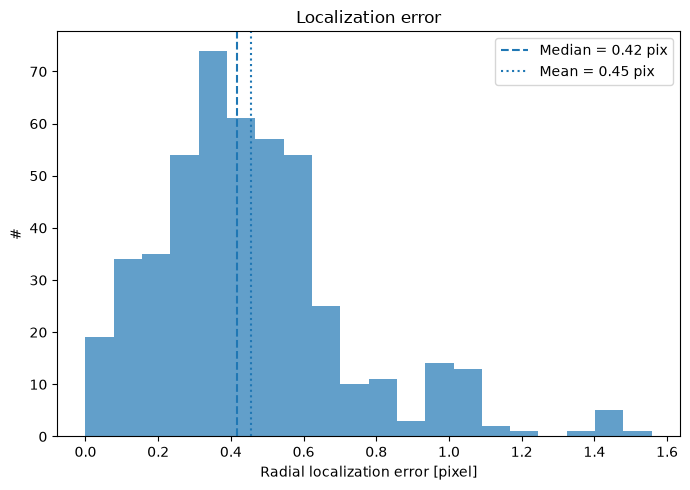

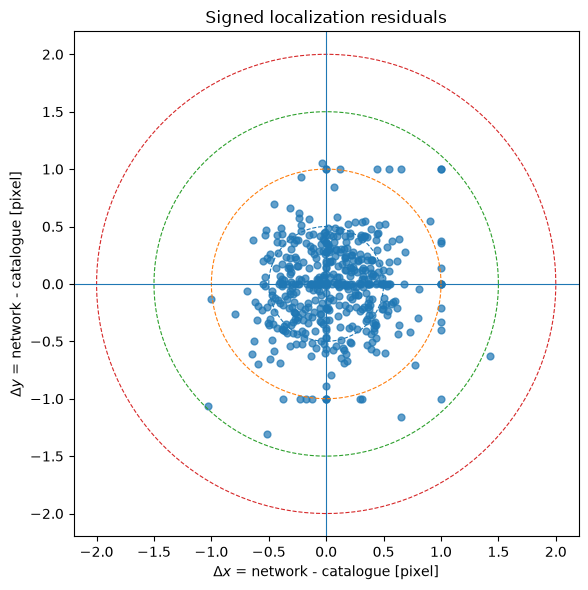

Mean signed offset: dx=0.060 pix, dy=-0.022 pix


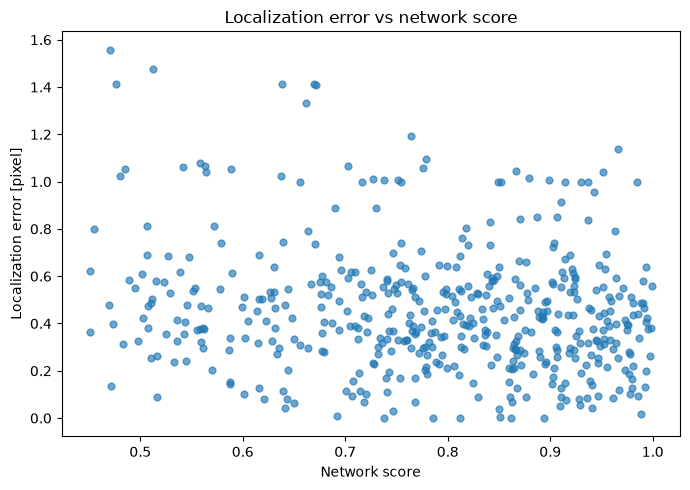

In [5]:
radial_error = matched["localization_error_pix"].dropna().to_numpy(float)

fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(radial_error, bins=20, alpha=0.7)
ax.axvline(np.median(radial_error), linestyle="--", label=f"Median = {np.median(radial_error):.2f} pix")
ax.axvline(np.mean(radial_error), linestyle=":", label=f"Mean = {np.mean(radial_error):.2f} pix")
ax.set(xlabel="Radial localization error [pixel]", ylabel="#", title="Localization error")
ax.legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))
dx = matched["localization_dx_pix"].to_numpy(float)
dy = matched["localization_dy_pix"].to_numpy(float)
ax.scatter(dx, dy, s=24, alpha=0.7)
theta = np.linspace(0, 2 * np.pi, 300)
for radius in (0.5, 1.0, 1.5, 2.0):
    ax.plot(radius * np.cos(theta), radius * np.sin(theta), linestyle="--", linewidth=0.8)
ax.axhline(0, linewidth=0.8)
ax.axvline(0, linewidth=0.8)
ax.set_aspect("equal", adjustable="box")
ax.set(xlabel=r"$\Delta x$ = network - catalogue [pixel]", ylabel=r"$\Delta y$ = network - catalogue [pixel]", title="Signed localization residuals")
fig.tight_layout()
plt.show()
print(f"Mean signed offset: dx={np.nanmean(dx):.3f} pix, dy={np.nanmean(dy):.3f} pix")

score_vs_error = matched.loc[np.isfinite(matched["network_score"]) & np.isfinite(matched["localization_error_pix"])]
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(score_vs_error["network_score"], score_vs_error["localization_error_pix"], s=24, alpha=0.65)
ax.set(xlabel="Network score", ylabel="Localization error [pixel]", title="Localization error vs network score")
fig.tight_layout()
plt.show()


## 5. Network score versus the real and synthetic PN domain

The synthetic points are read from `metadata_json`; the network is not rerun. The comparison tests whether missed real PNe occupy Hα/[O III]–$m_{5007}$ regions that are poorly represented in the synthetic training population.


In [11]:
DOMAIN_COLUMNS = {"population", "object_id", "network_score", "ha_over_oiii","hb_over_oiii", "catalog_m5007", "edge_object"}
require_columns(diagnostic_table, DOMAIN_COLUMNS, "Domain diagnostic")

real_mask = diagnostic_table["population"].isin(REAL_PN_POPULATIONS) & ~diagnostic_table["edge_object"].fillna(True)
real_pn_domain = diagnostic_table.loc[real_mask].copy()
real_pn_domain = real_pn_domain.loc[
    np.isfinite(real_pn_domain["network_score"])
    & np.isfinite(real_pn_domain["ha_over_oiii"])
    & real_pn_domain["ha_over_oiii"].gt(0)
    & np.isfinite(real_pn_domain["catalog_m5007"])
].copy()


def load_synthetic_pn_domain(path):
    with np.load(path, allow_pickle=True) as synth_npz:
        if "metadata_json" not in synth_npz:
            raise KeyError(f"{path} has no metadata_json field.")
        metadata = json.loads(synth_npz["metadata_json"].item())

    rows = []
    for sample in metadata:
        for source in sample.get("sources", []):
            if str(source.get("class", "")).upper() != "PN":
                continue
            fluxes = source.get("line_fluxes", {})
            ha = float(fluxes.get("Halpha", np.nan))
            hb = float(fluxes.get("Hbeta", np.nan))
            oiii = float(fluxes.get("OIII5007", np.nan))
            m5007 = float(source.get("m5007", np.nan))
            if np.isfinite(ha) and np.isfinite(oiii) and oiii > 0 and np.isfinite(m5007):
                rows.append({
                "hb_over_oiii": hb / oiii if np.isfinite(hb) and hb > 0 else np.nan,
                "ha_over_oiii": ha / oiii if np.isfinite(ha) and ha > 0 else np.nan,
                "m5007": m5007})

    domain = pd.DataFrame(rows)
    if domain.empty:
        raise ValueError("No PN source metadata could be extracted from the synthetic dataset.")
    return domain


synthetic_pn_domain = load_synthetic_pn_domain(SYNTHETIC_DATASET)
syn_ratio_lo, syn_ratio_hi = np.min(synthetic_pn_domain["ha_over_oiii"]), np.max(synthetic_pn_domain["ha_over_oiii"])
syn_hbratio_lo, syn_hbratio_hi = np.min(synthetic_pn_domain["hb_over_oiii"]), np.max(synthetic_pn_domain["hb_over_oiii"])
syn_mag_lo, syn_mag_hi = np.min(synthetic_pn_domain["m5007"]), np.max(synthetic_pn_domain["m5007"])

real_pn_domain["inside_synthetic_1_99_box"] = (
    real_pn_domain["ha_over_oiii"].between(syn_ratio_lo, syn_ratio_hi)
    & real_pn_domain["catalog_m5007"].between(syn_mag_lo, syn_mag_hi))

domain_coverage = (
    real_pn_domain.groupby("population")
    .agg(
        N=("object_id", "size"),
        median_network_score=("network_score", "median"),
        median_ha_over_oiii=("ha_over_oiii", "median"),
        median_m5007=("catalog_m5007", "median"),
        fraction_inside_synthetic_1_99_box=("inside_synthetic_1_99_box", "mean"))
    .reset_index())
domain_coverage.to_csv(OUTPUT_DIR / "real_vs_synthetic_domain_coverage.csv", index=False)

print(f"Real catalogue PNe: {len(real_pn_domain)}")
print(f"Synthetic PN sources: {len(synthetic_pn_domain)}")
print(f"Synthetic 1–99% Ha/[O III]: {syn_ratio_lo:.3g} to {syn_ratio_hi:.3g}")
print(f"Synthetic 1–99% Hb/[O III]: {syn_hbratio_lo:.3g} to {syn_hbratio_hi:.3g}")
print(f"Synthetic 1–99% m5007: {syn_mag_lo:.2f} to {syn_mag_hi:.2f}")
display(domain_coverage)


Real catalogue PNe: 526
Synthetic PN sources: 15899
Synthetic 1–99% Ha/[O III]: 0.113 to 5.6
Synthetic 1–99% Hb/[O III]: 0.034 to 0.85
Synthetic 1–99% m5007: 22.00 to 28.00


,population,N,median_network_score,median_ha_over_oiii,median_m5007,fraction_inside_synthetic_1_99_box
0,Missed catalogue PN,92,0.262532,0.770889,25.9185,0.978261
1,Recovered catalogue PN,434,0.797976,0.314960,25.2165,0.981567


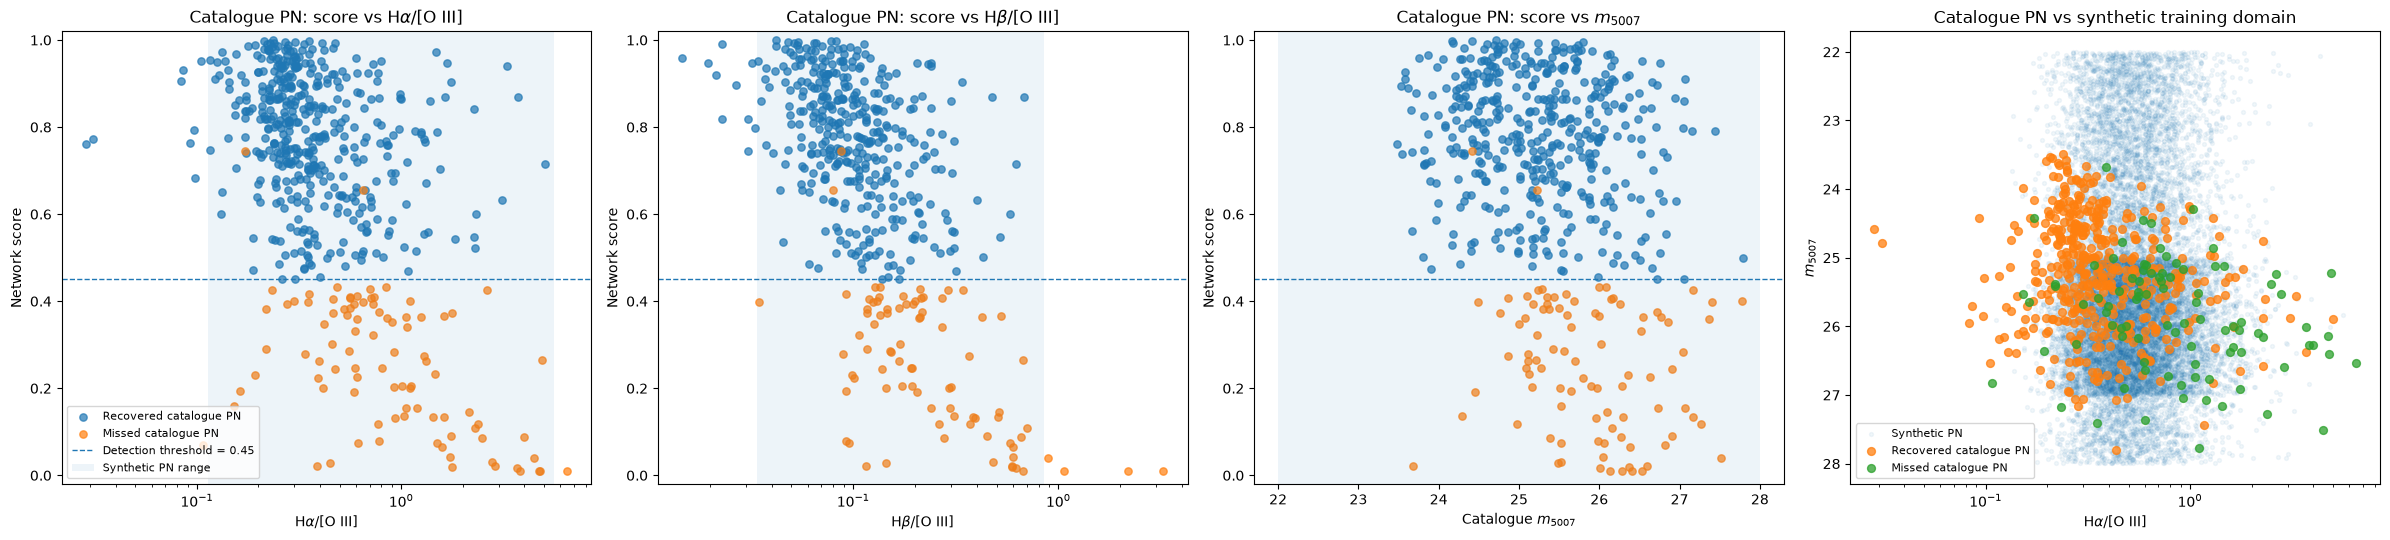

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5.5))

for population in REAL_PN_POPULATIONS:
    group = real_pn_domain.loc[real_pn_domain["population"].eq(population)]
    axes[0].scatter(group["ha_over_oiii"], group["network_score"], s=28, alpha=0.70, label=population)
    axes[1].scatter(group["hb_over_oiii"], group["network_score"], s=28, alpha=0.70, label=population)
    axes[2].scatter(group["catalog_m5007"], group["network_score"], s=28, alpha=0.70, label=population)

axes[0].axhline(DETECTION_THRESHOLD, linestyle="--", linewidth=1.0, label=f"Detection threshold = {DETECTION_THRESHOLD:.2f}")
axes[0].axvspan(syn_ratio_lo, syn_ratio_hi, alpha=0.08, label="Synthetic PN range")
axes[0].set_xscale("log")
axes[0].set(xlabel=r"H$\alpha$/[O III]", ylabel="Network score", title=r"Catalogue PN: score vs H$\alpha$/[O III]", ylim=(-0.02, 1.02))
axes[0].legend(fontsize=8)

axes[1].axhline(DETECTION_THRESHOLD, linestyle="--", linewidth=1.0, label=f"Detection threshold = {DETECTION_THRESHOLD:.2f}")
axes[1].axvspan(syn_hbratio_lo, syn_hbratio_hi, alpha=0.08)
axes[1].set_xscale("log")
axes[1].set(xlabel=r"H$\beta$/[O III]", ylabel="Network score", title=r"Catalogue PN: score vs H$\beta$/[O III]", ylim=(-0.02, 1.02))

axes[2].axhline(DETECTION_THRESHOLD, linestyle="--", linewidth=1.0)
axes[2].axvspan(syn_mag_lo, syn_mag_hi, alpha=0.08)
axes[2].set(xlabel=r"Catalogue $m_{5007}$", ylabel="Network score", title=r"Catalogue PN: score vs $m_{5007}$", ylim=(-0.02, 1.02))

axes[3].scatter(synthetic_pn_domain["ha_over_oiii"], synthetic_pn_domain["m5007"], s=8, alpha=0.06, rasterized=True, label="Synthetic PN")
for population in REAL_PN_POPULATIONS:
    group = real_pn_domain.loc[real_pn_domain["population"].eq(population)]
    axes[3].scatter(group["ha_over_oiii"], group["catalog_m5007"], s=32, alpha=0.75, label=population)
axes[3].set_xscale("log")
axes[3].invert_yaxis()
axes[3].set(xlabel=r"H$\alpha$/[O III]", ylabel=r"$m_{5007}$", title="Catalogue PN vs synthetic training domain")
axes[3].legend(fontsize=8)

#fig.suptitle("PN recovery as a function of spectral ratio and brightness", fontsize=14)
fig.tight_layout()
#domain_plot_path = OUTPUT_DIR / "network_score_vs_real_synthetic_domain.png"
domain_plot_path = "./network_score_vs_real_synthetic_domain.png"
fig.savefig(domain_plot_path, dpi=180, bbox_inches="tight")
plt.show()


## 6. Score-stratified visual samples

Each population contributes up to 10 objects from each of three score bins. Edge objects are excluded so complete centered cutouts can be shown.


In [8]:
sample_specs = (
    (POP_MATCHED, DETECTED_SCORE_BINS, RANDOM_SEED),
    (POP_MISSED, MISSED_SCORE_BINS, RANDOM_SEED + 200),
    (POP_UNMATCHED, DETECTED_SCORE_BINS, RANDOM_SEED + 100),
)

samples_by_population = {
    population: sample_score_bins(diagnostic_table, population, bins, N_PER_SCORE_BIN, seed)
    for population, bins, seed in sample_specs
}
visual_sample = pd.concat(samples_by_population.values(), ignore_index=True)
visual_sample.to_csv(OUTPUT_DIR / "visual_sample_30_each.csv", index=False)

display(visual_sample.groupby(["population", "score_bin"]).size().rename("N").reset_index())


,population,score_bin,N
0,Missed catalogue PN,0.15–0.30,10
1,Missed catalogue PN,0.30–0.45,10
2,Missed catalogue PN,<0.15,10
3,Recovered catalogue PN,0.45–0.60,10
4,Recovered catalogue PN,0.60–0.80,10
5,Recovered catalogue PN,>=0.80,10
6,Unmatched candidate,0.45–0.60,10
7,Unmatched candidate,0.60–0.80,10
8,Unmatched candidate,>=0.80,10


## 7. Multi-channel cutout grids

Each row is one object and each column is Hβ, [O III], Hα, [N II], or their sum. Every panel uses its own asinh normalization and colorbar in the original flux units.


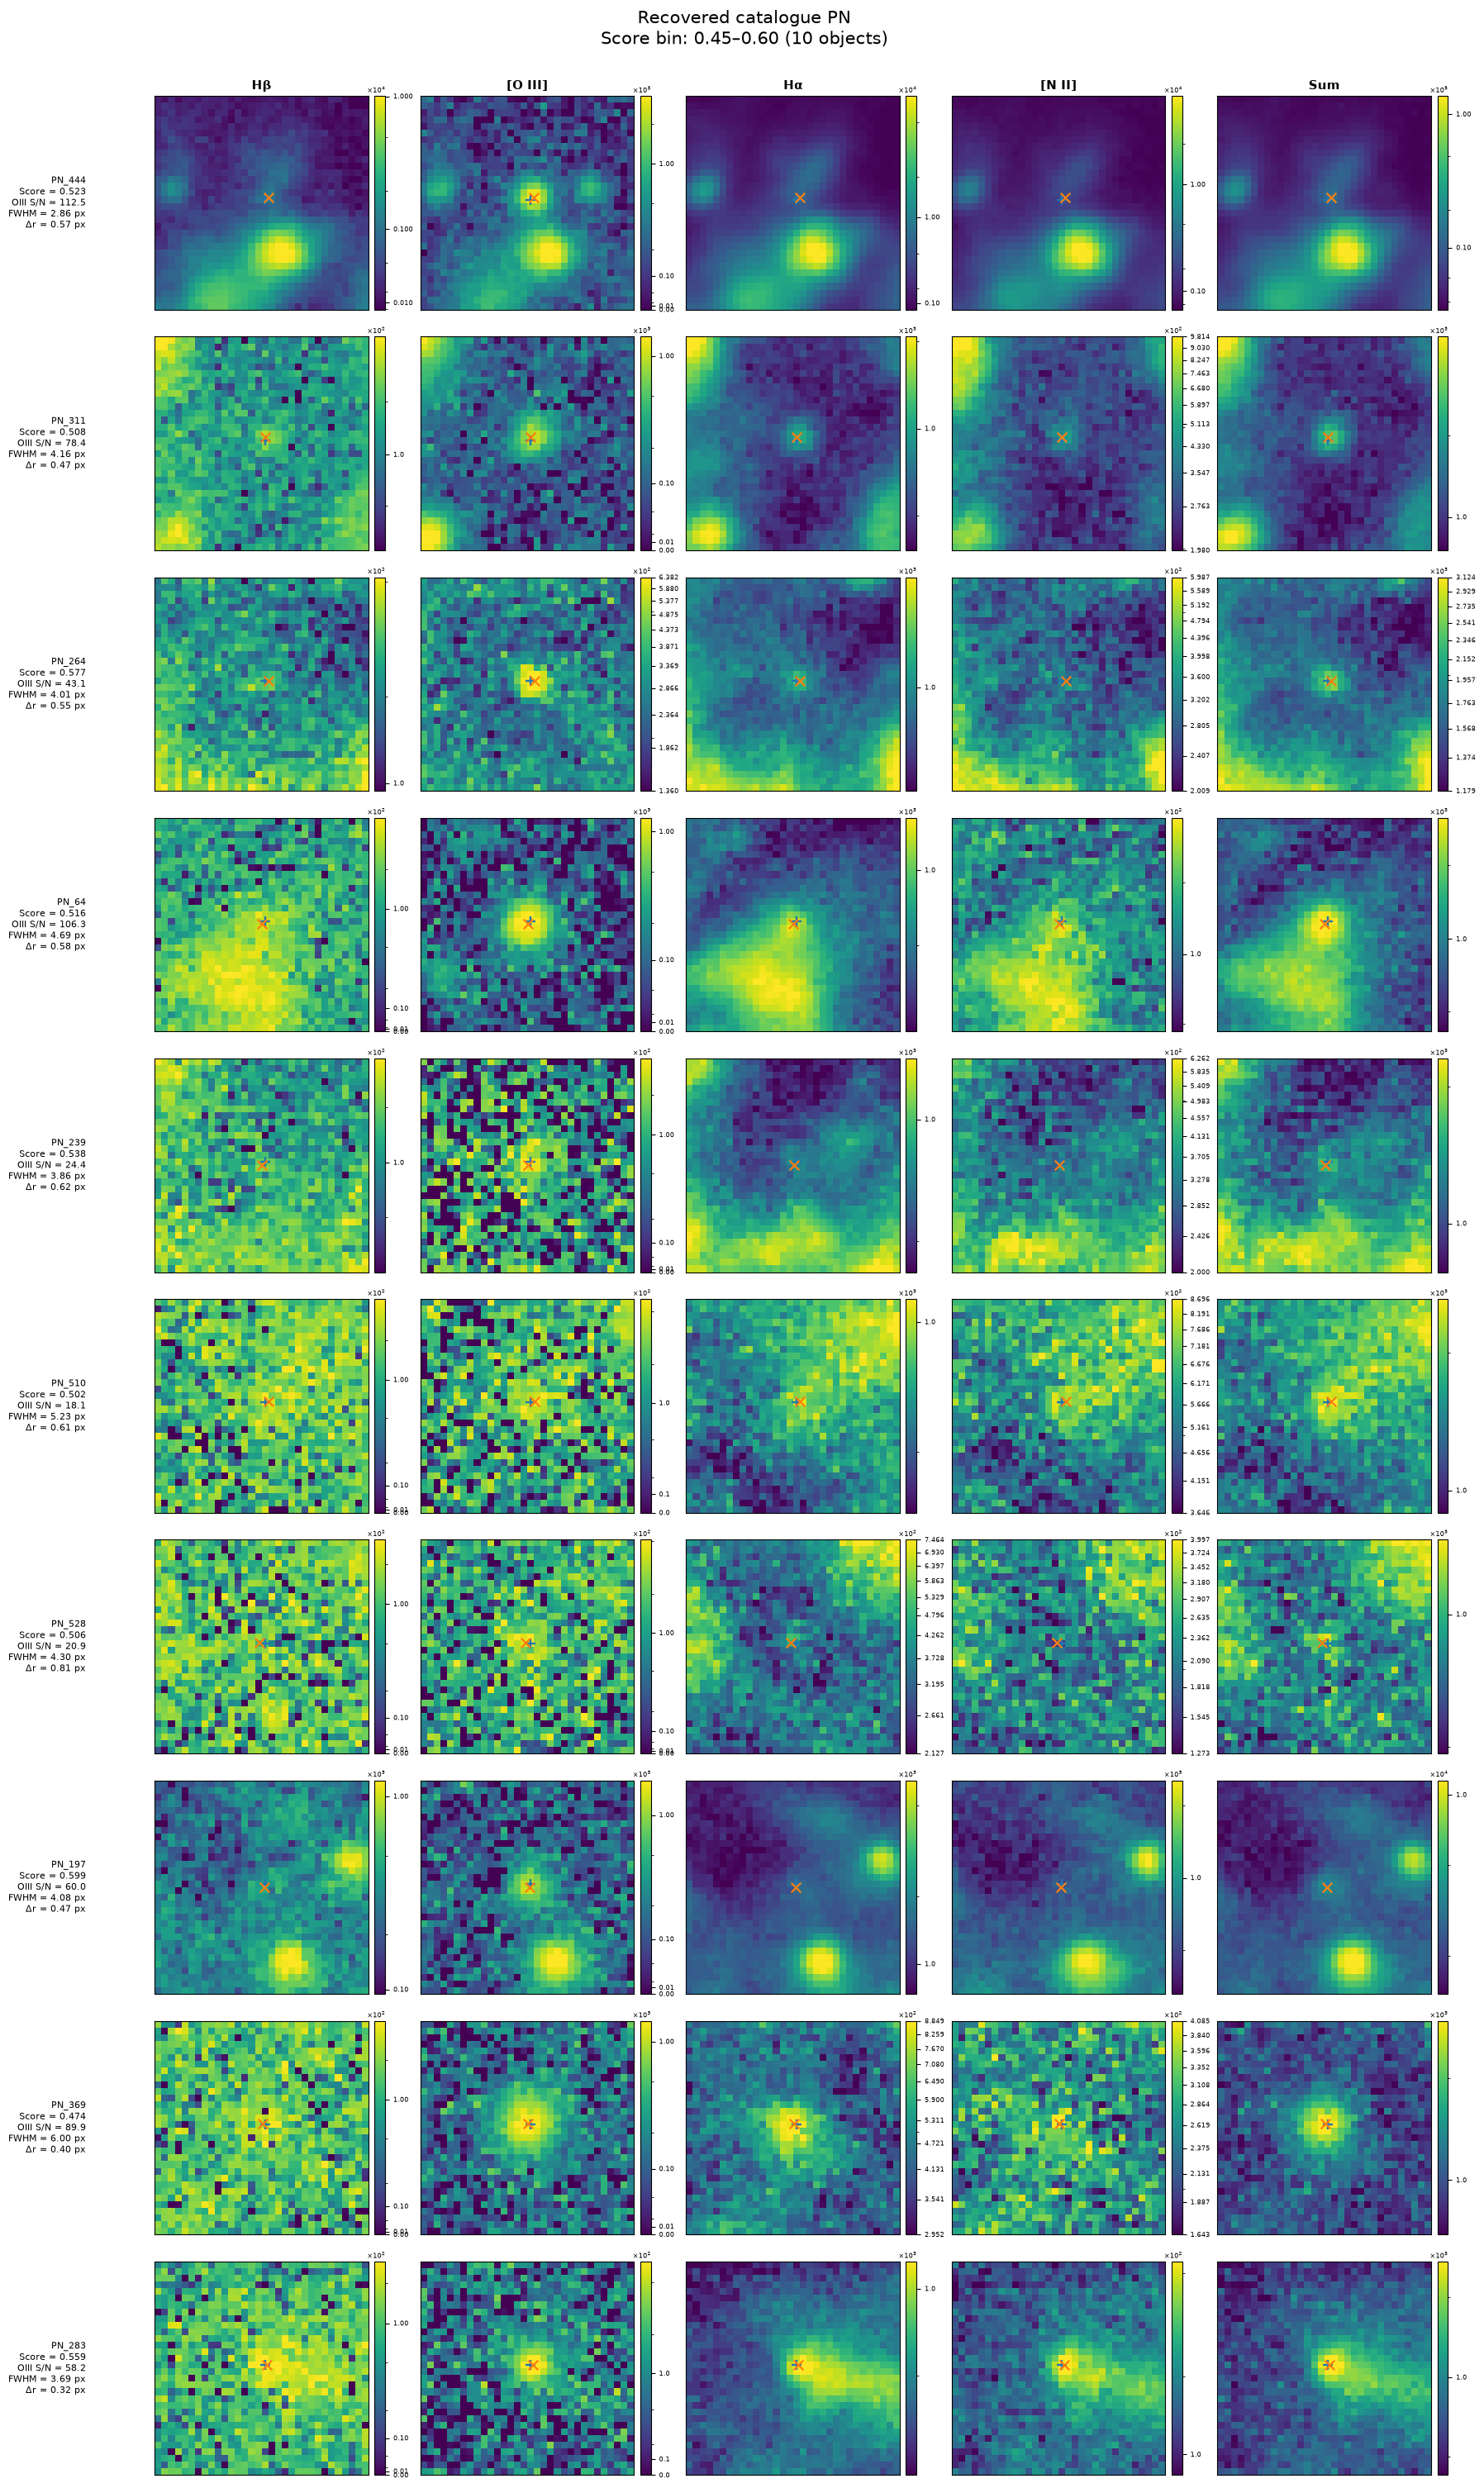

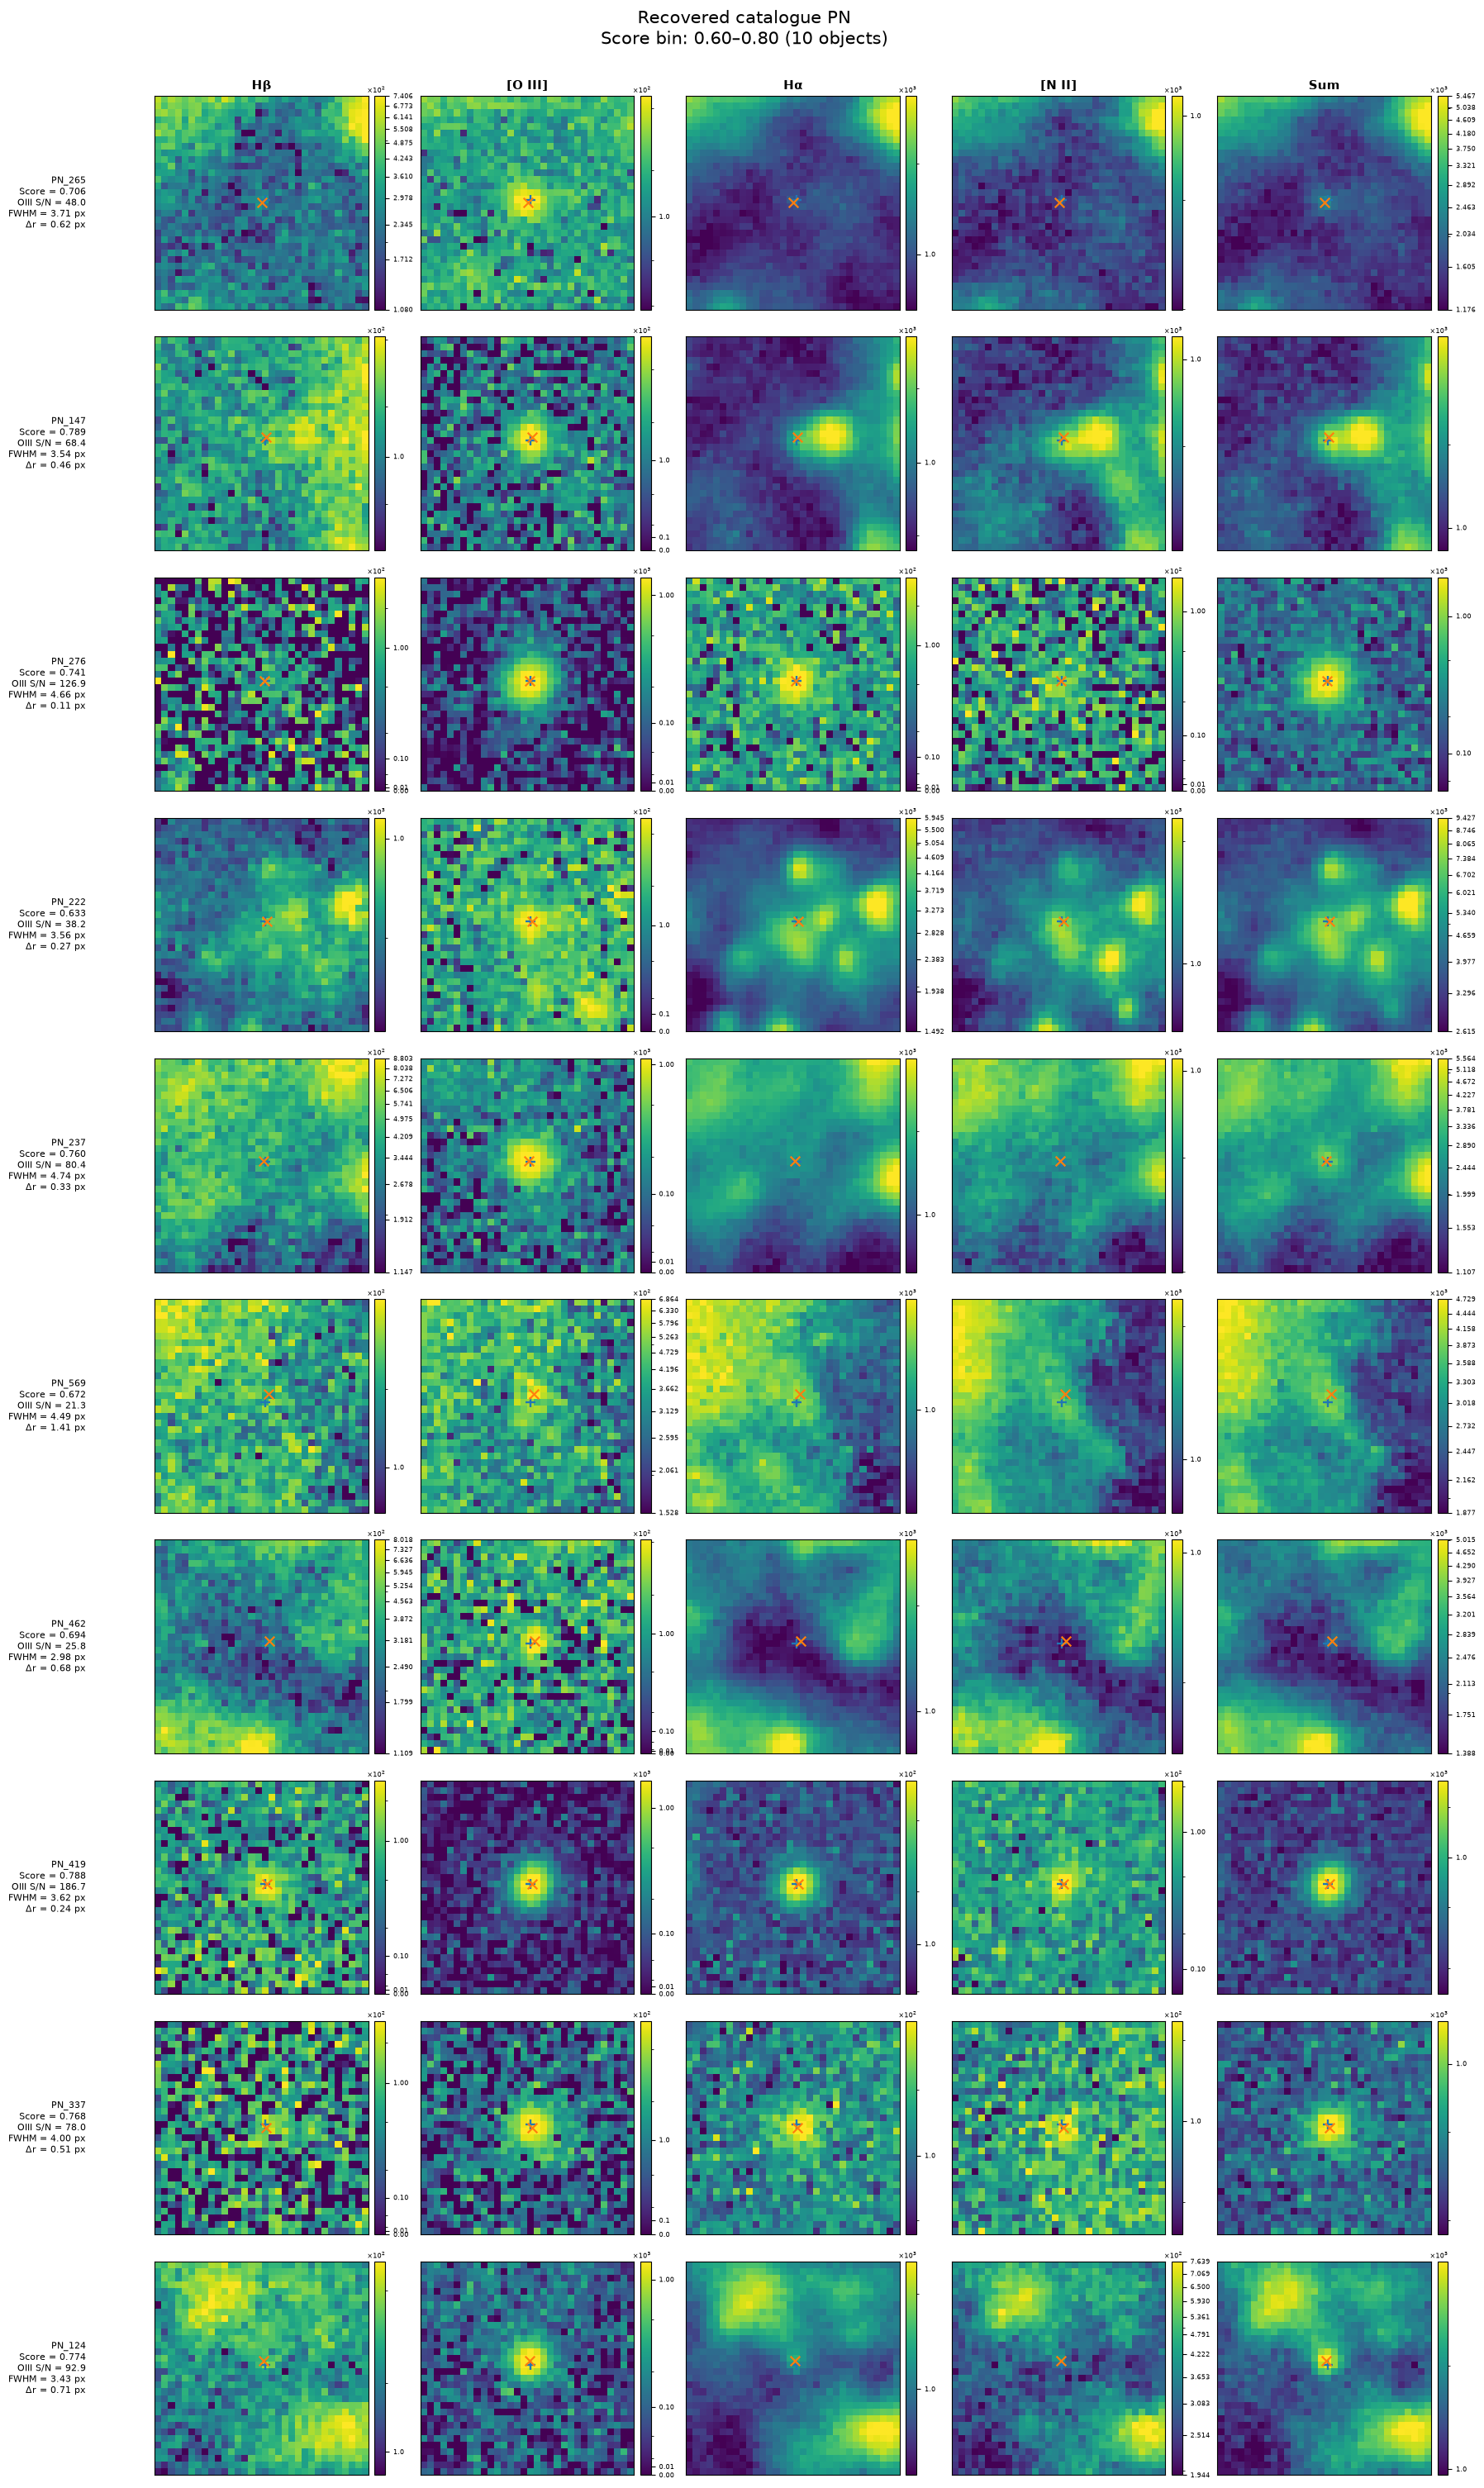

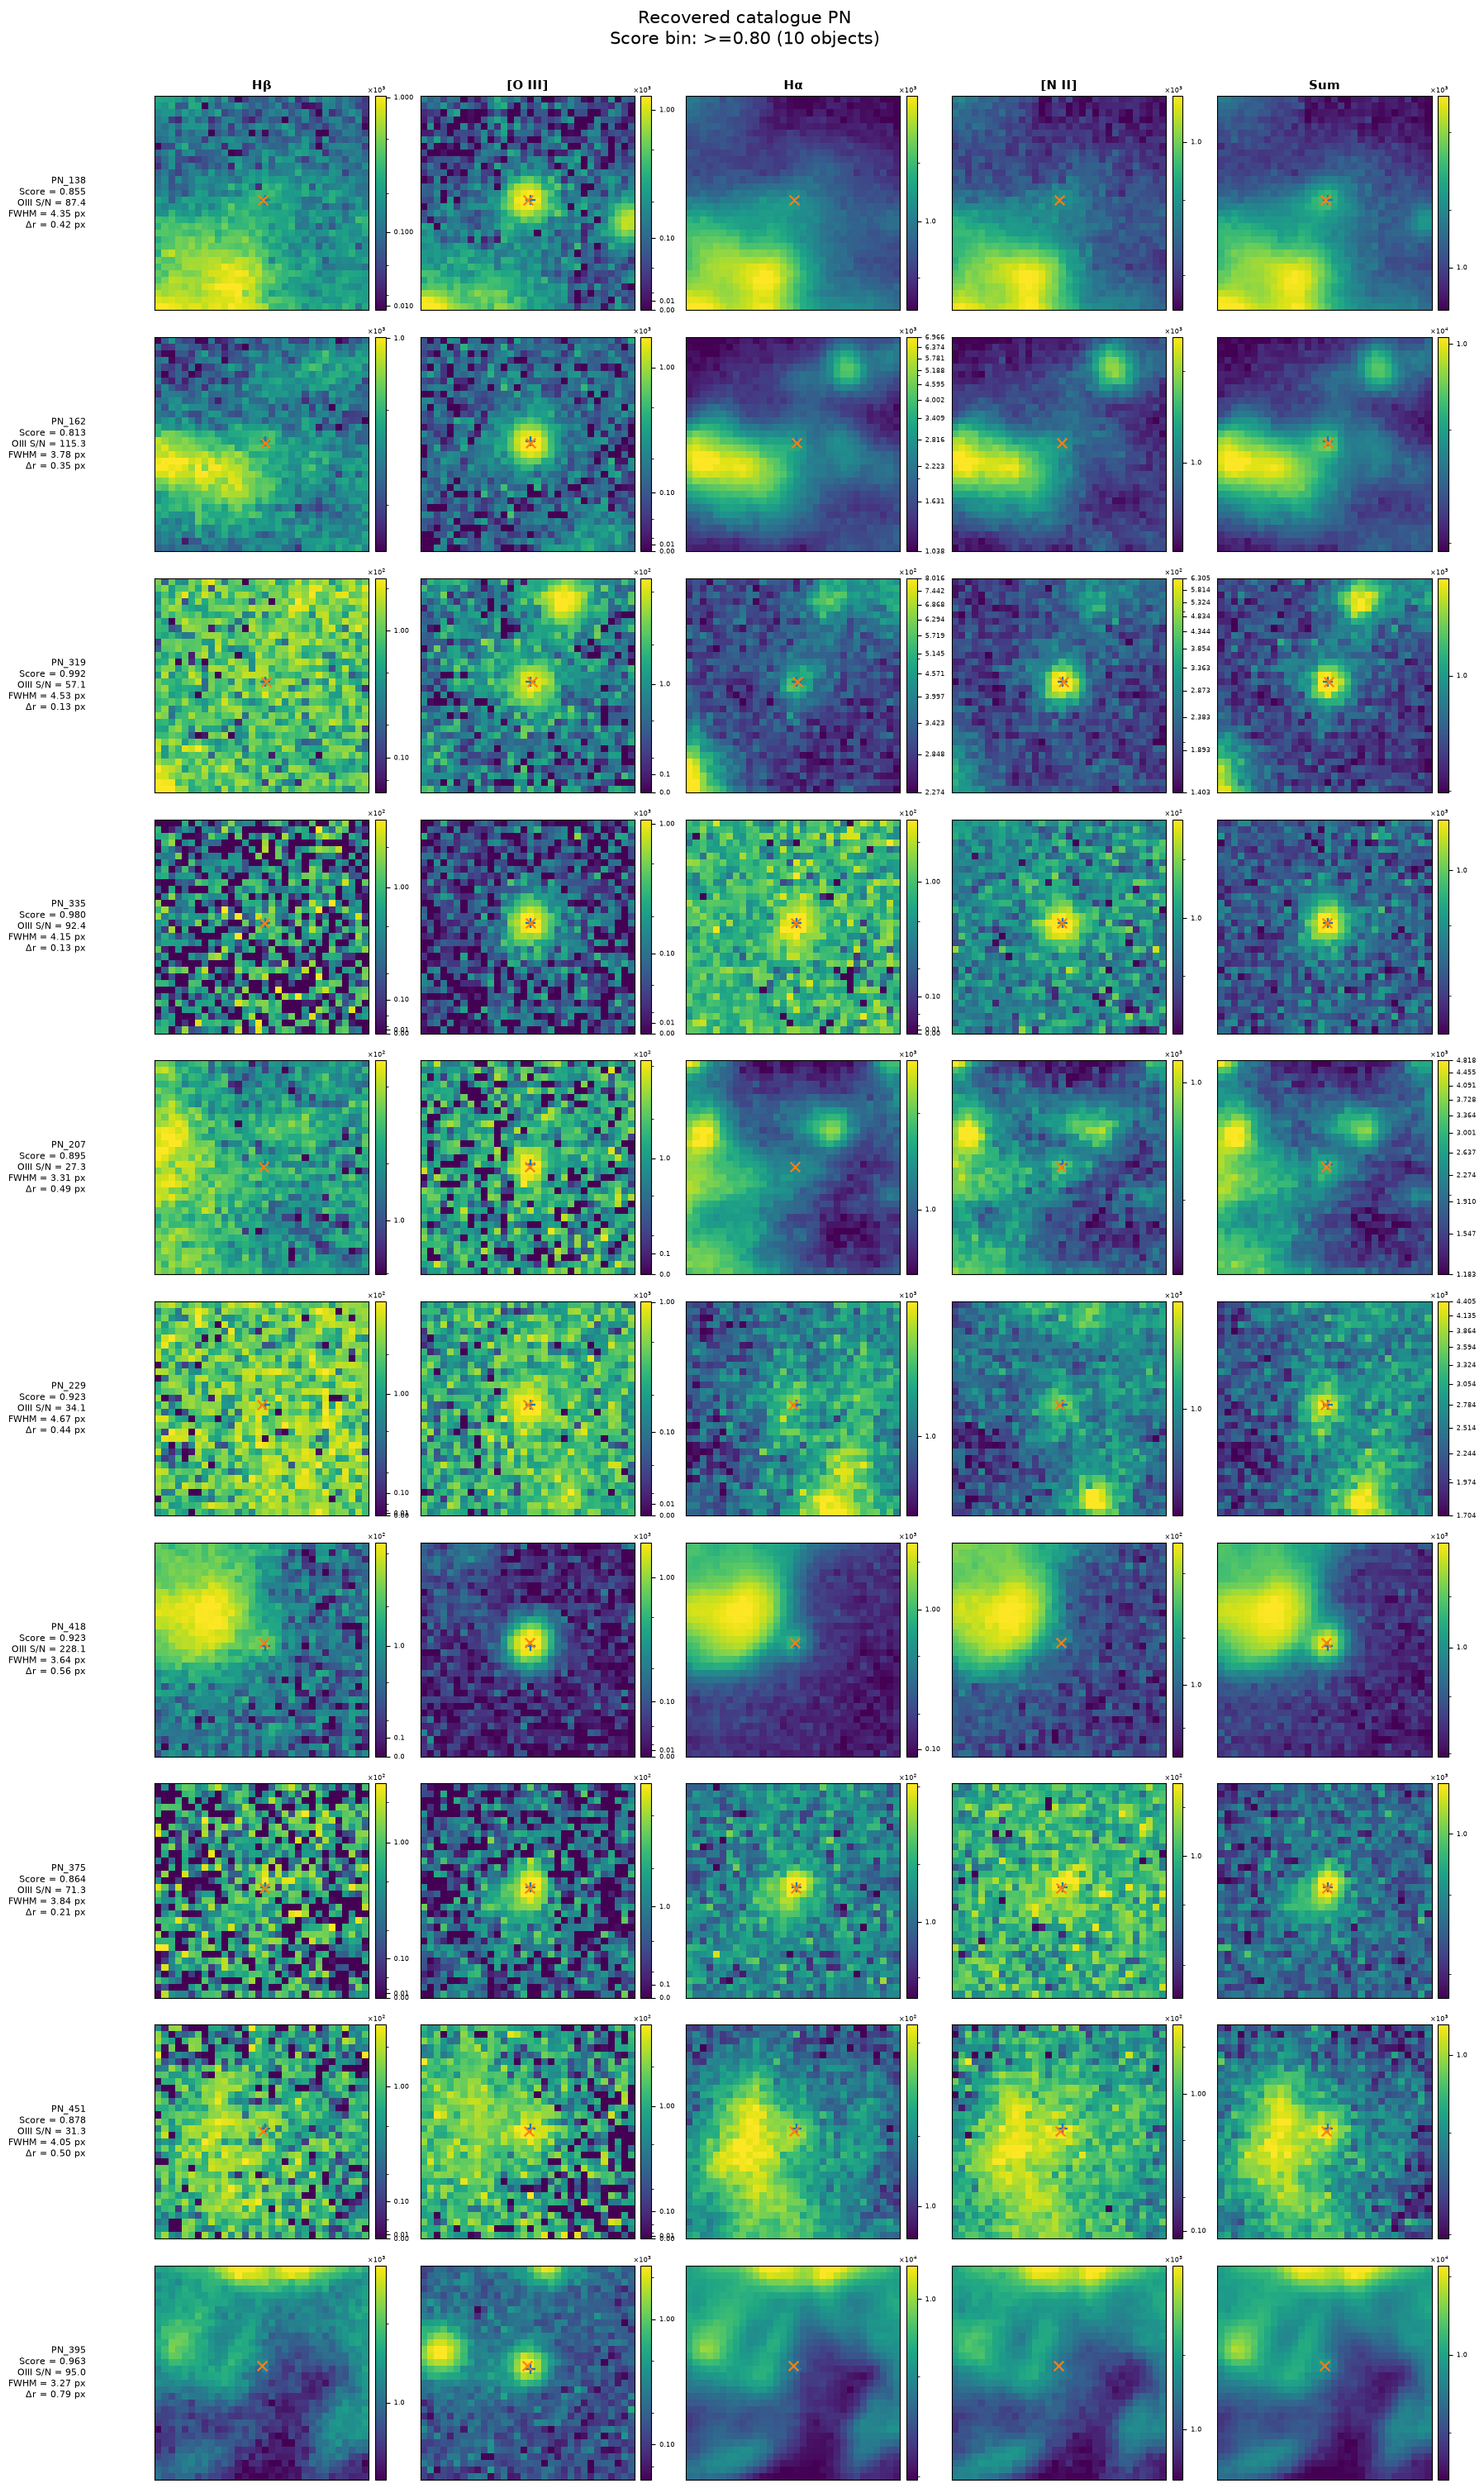

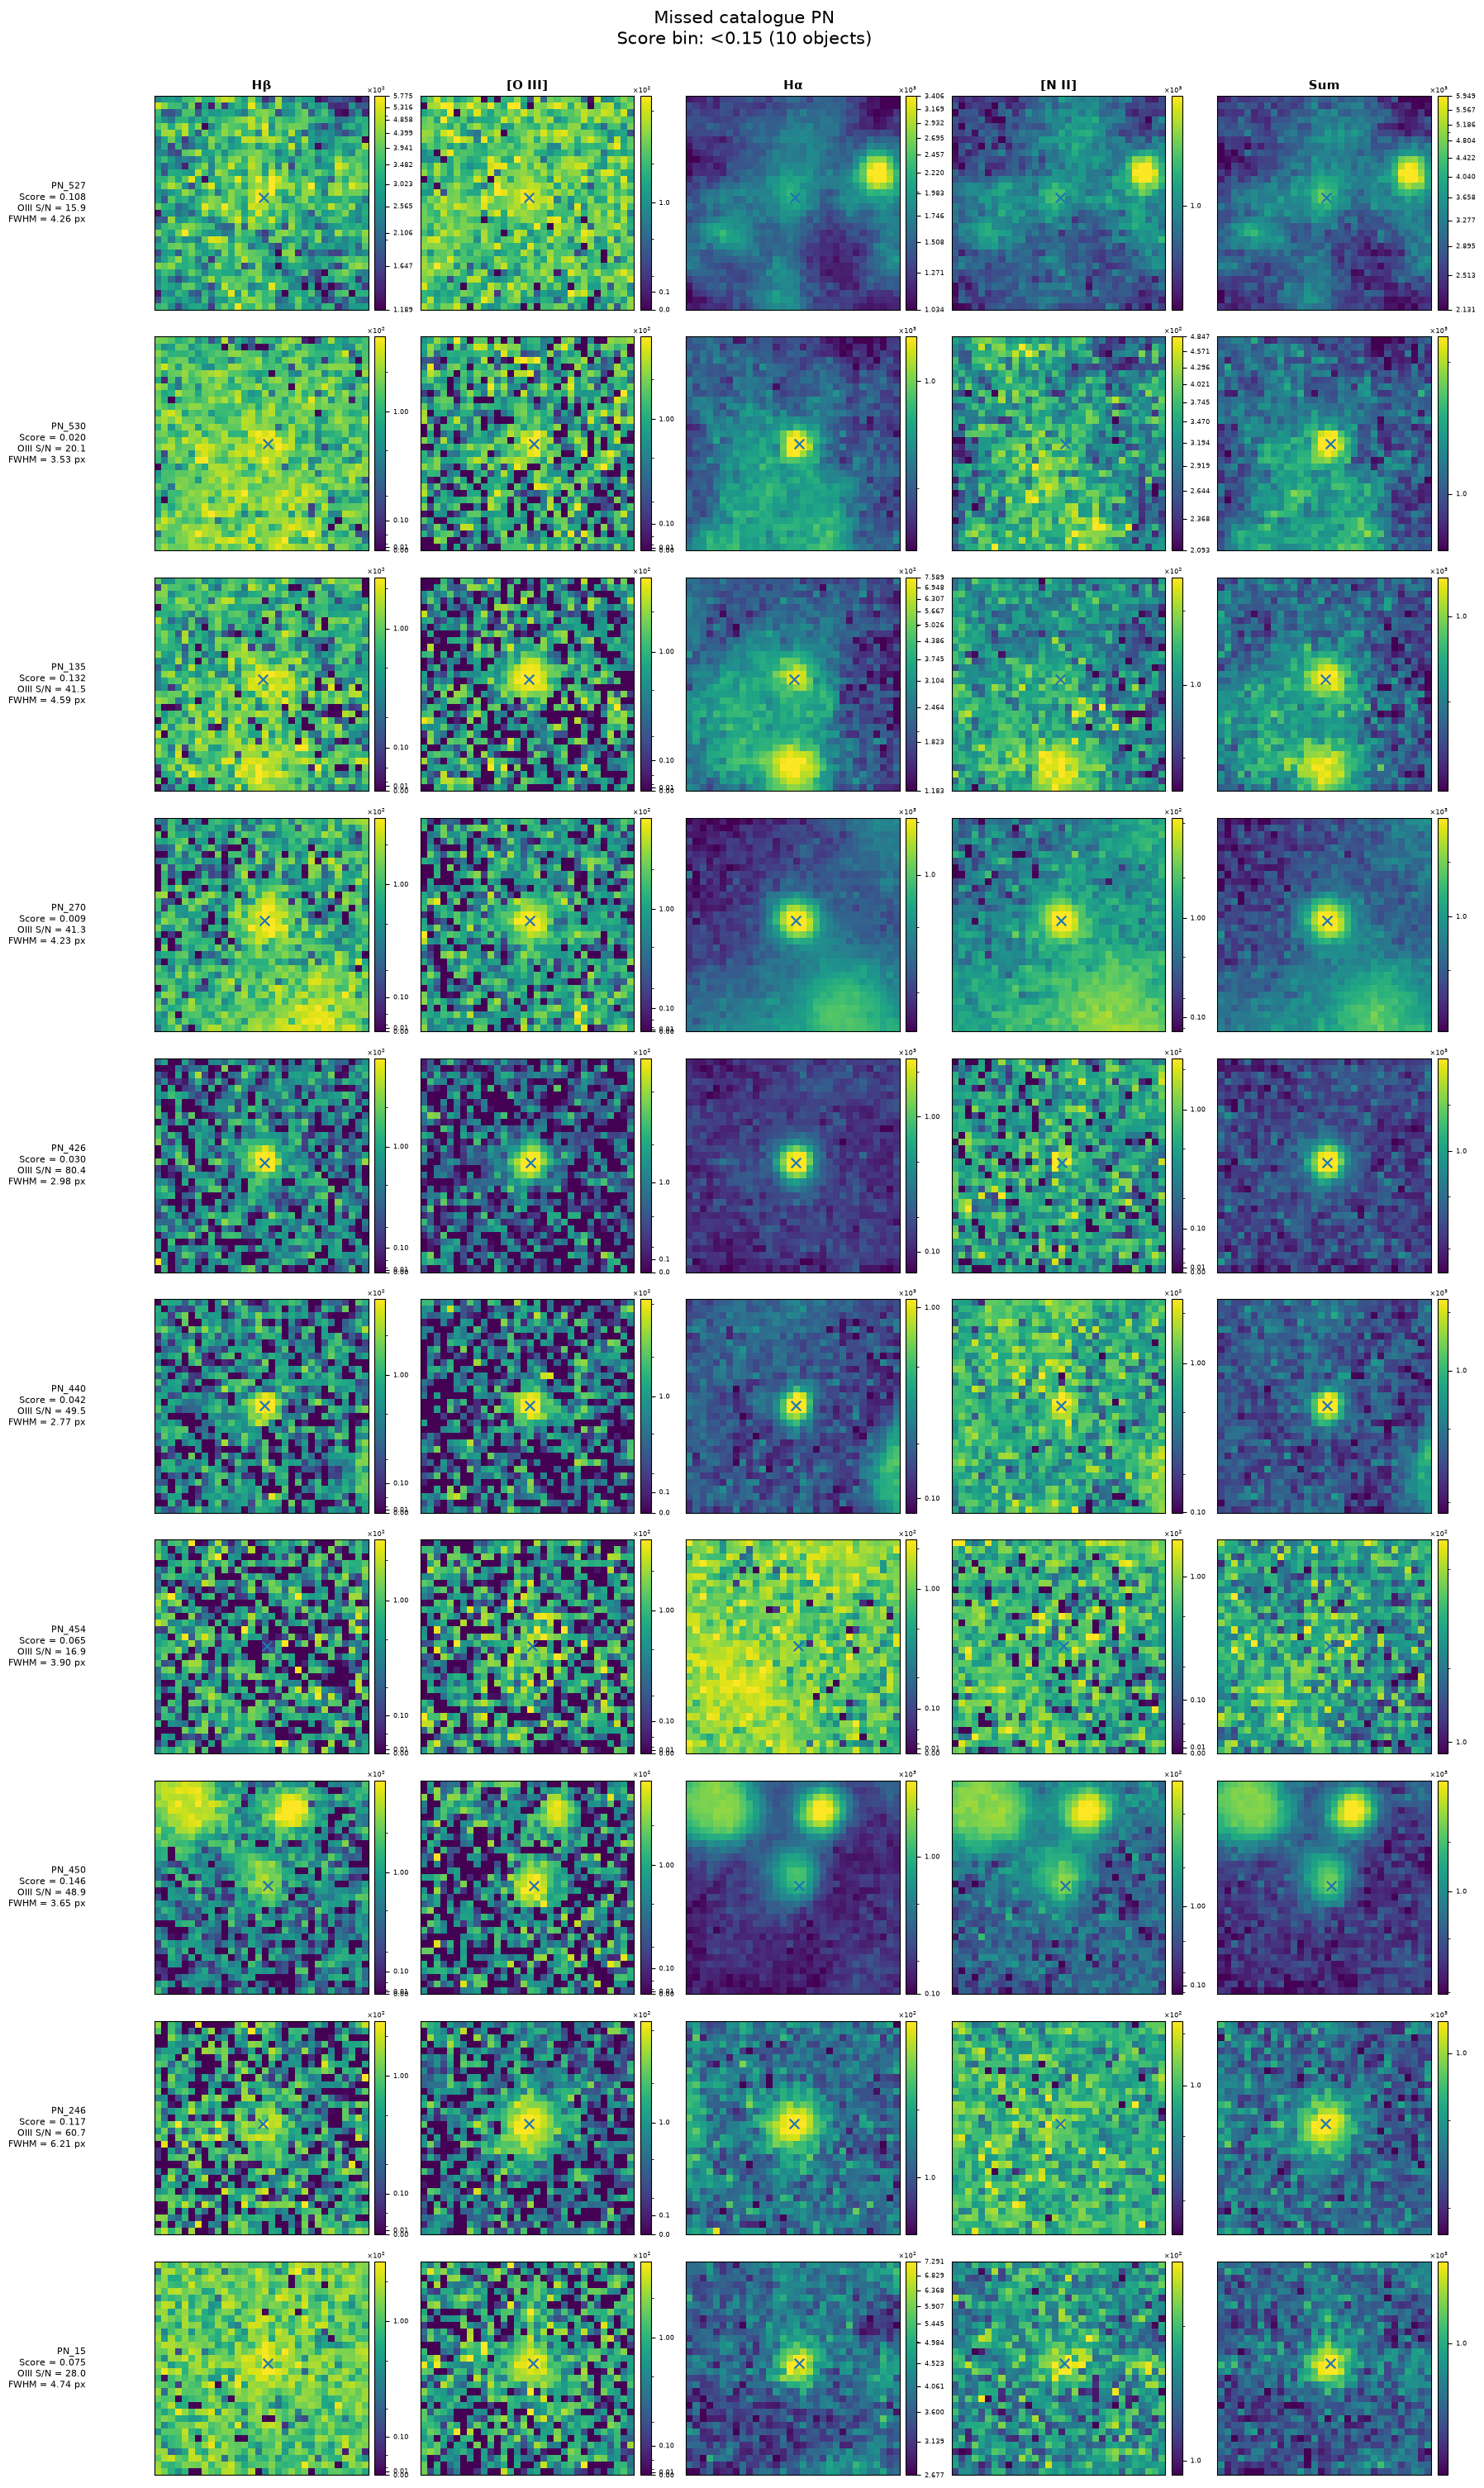

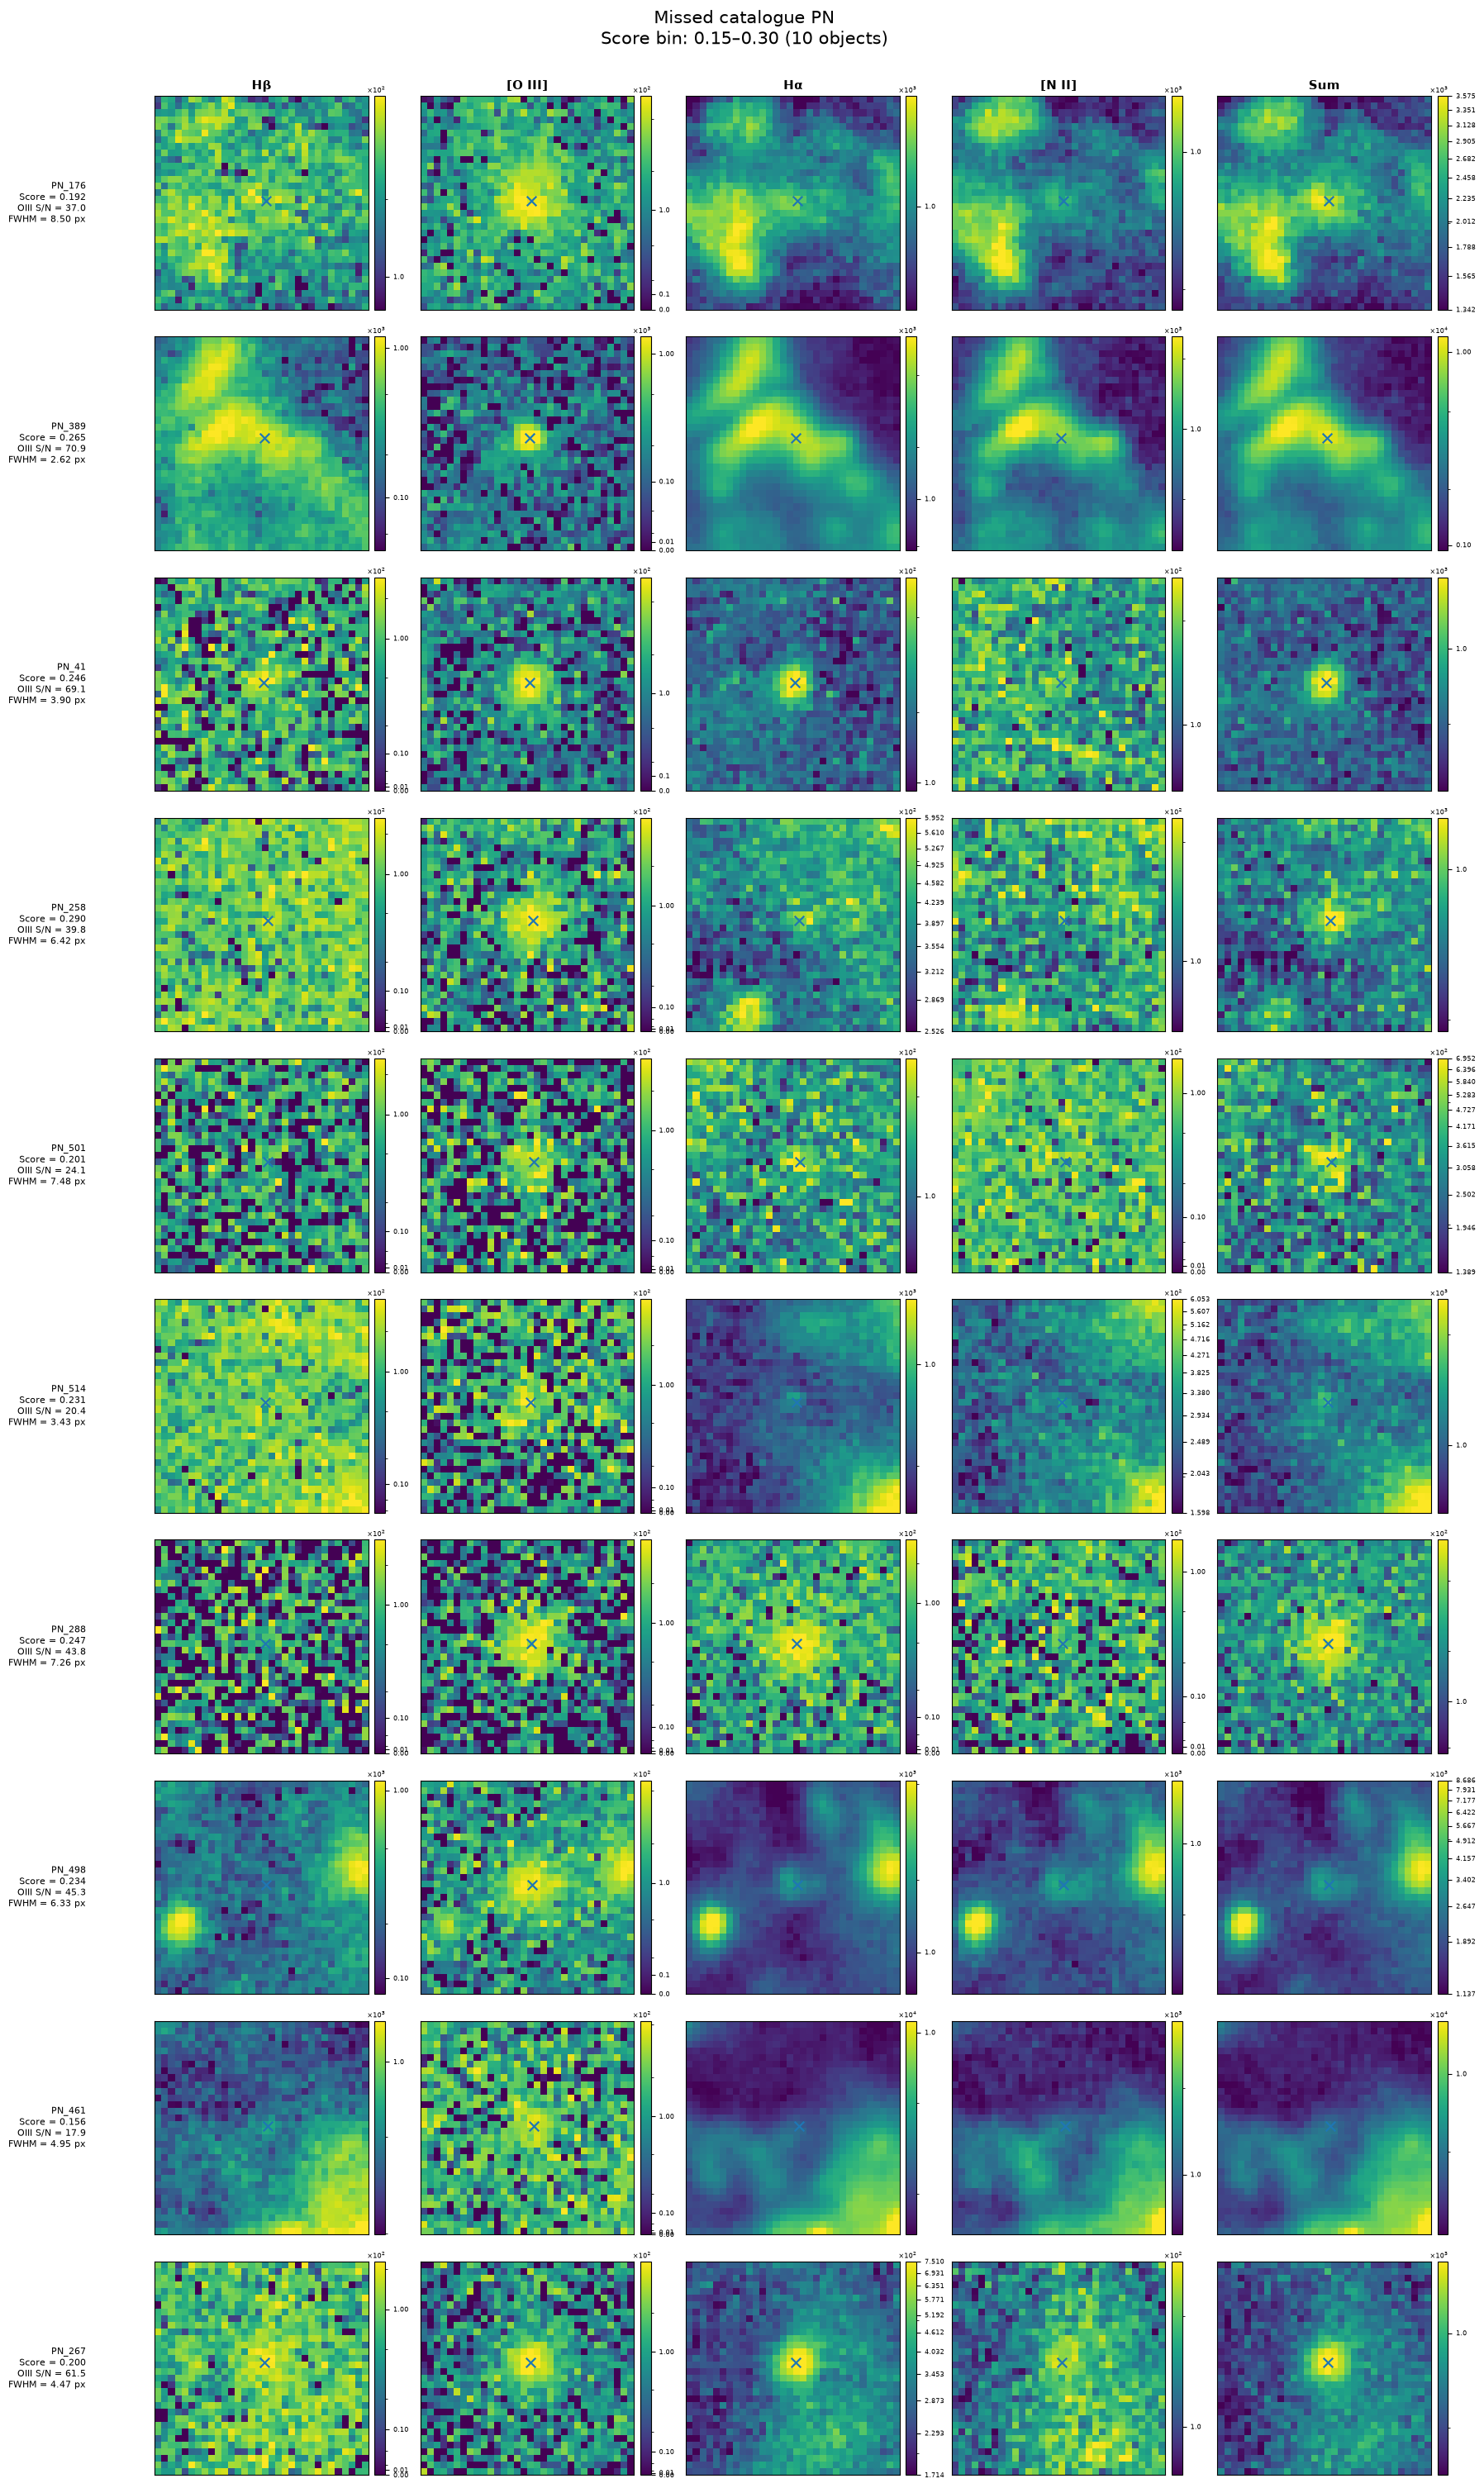

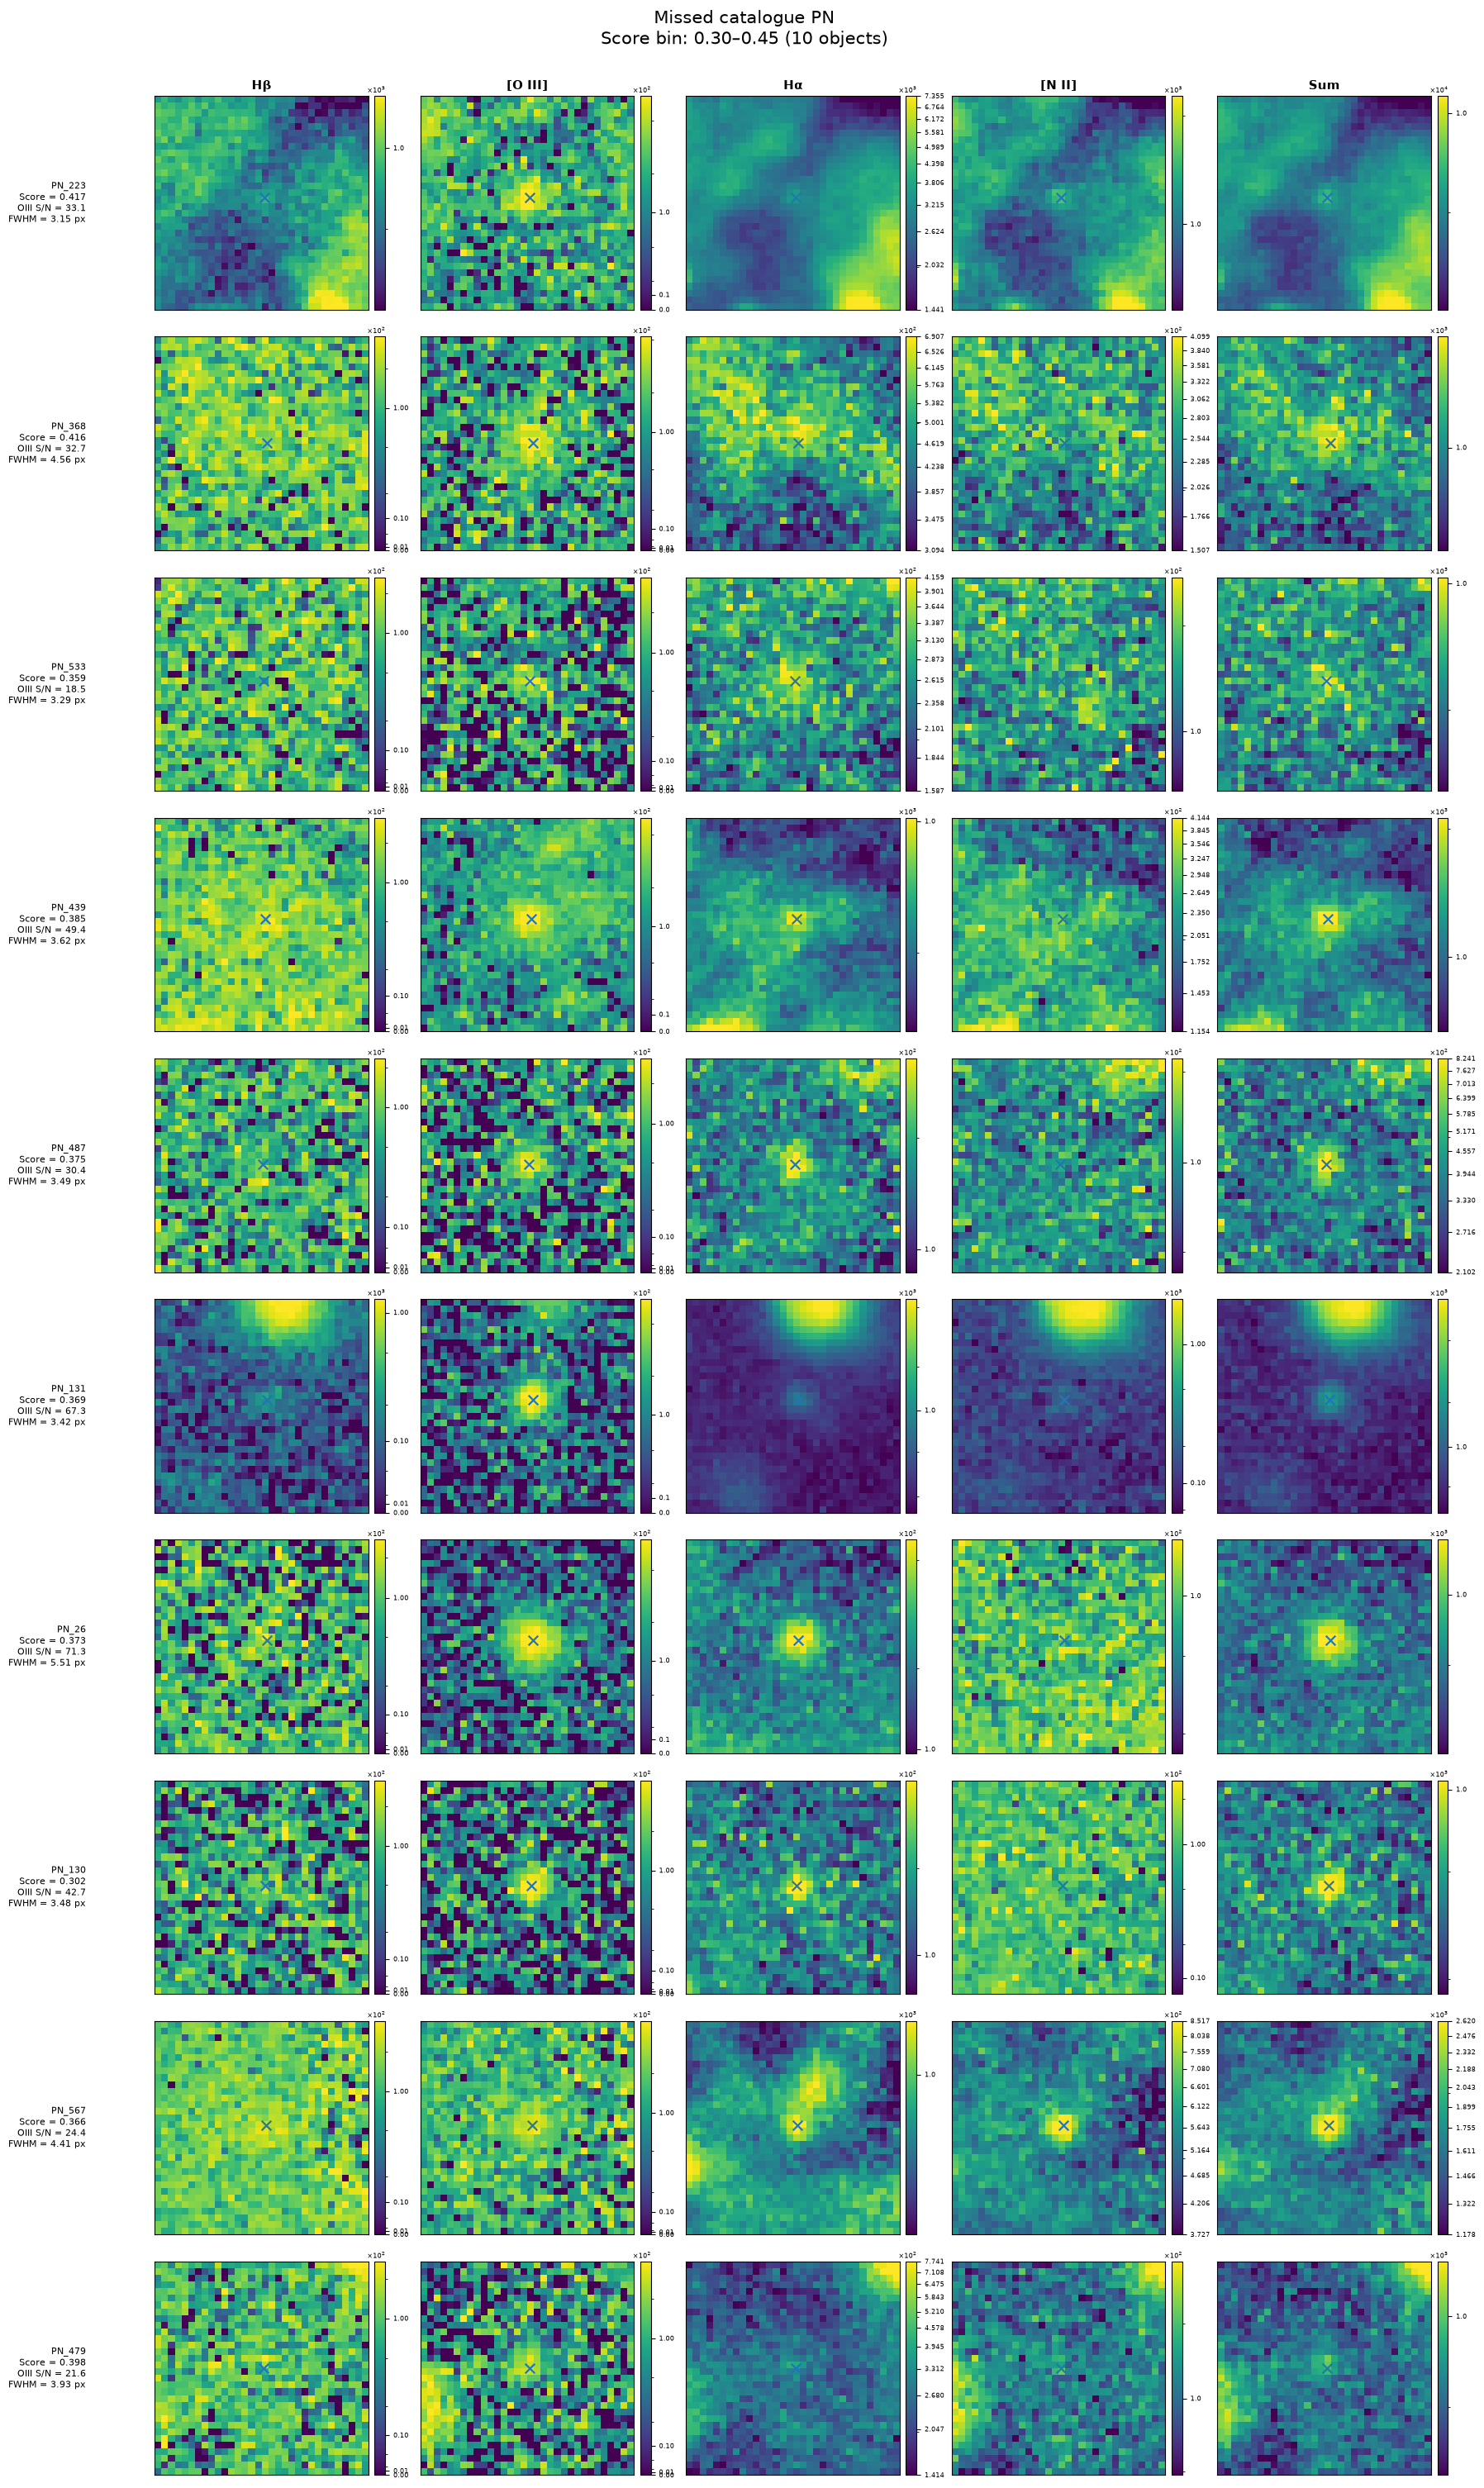

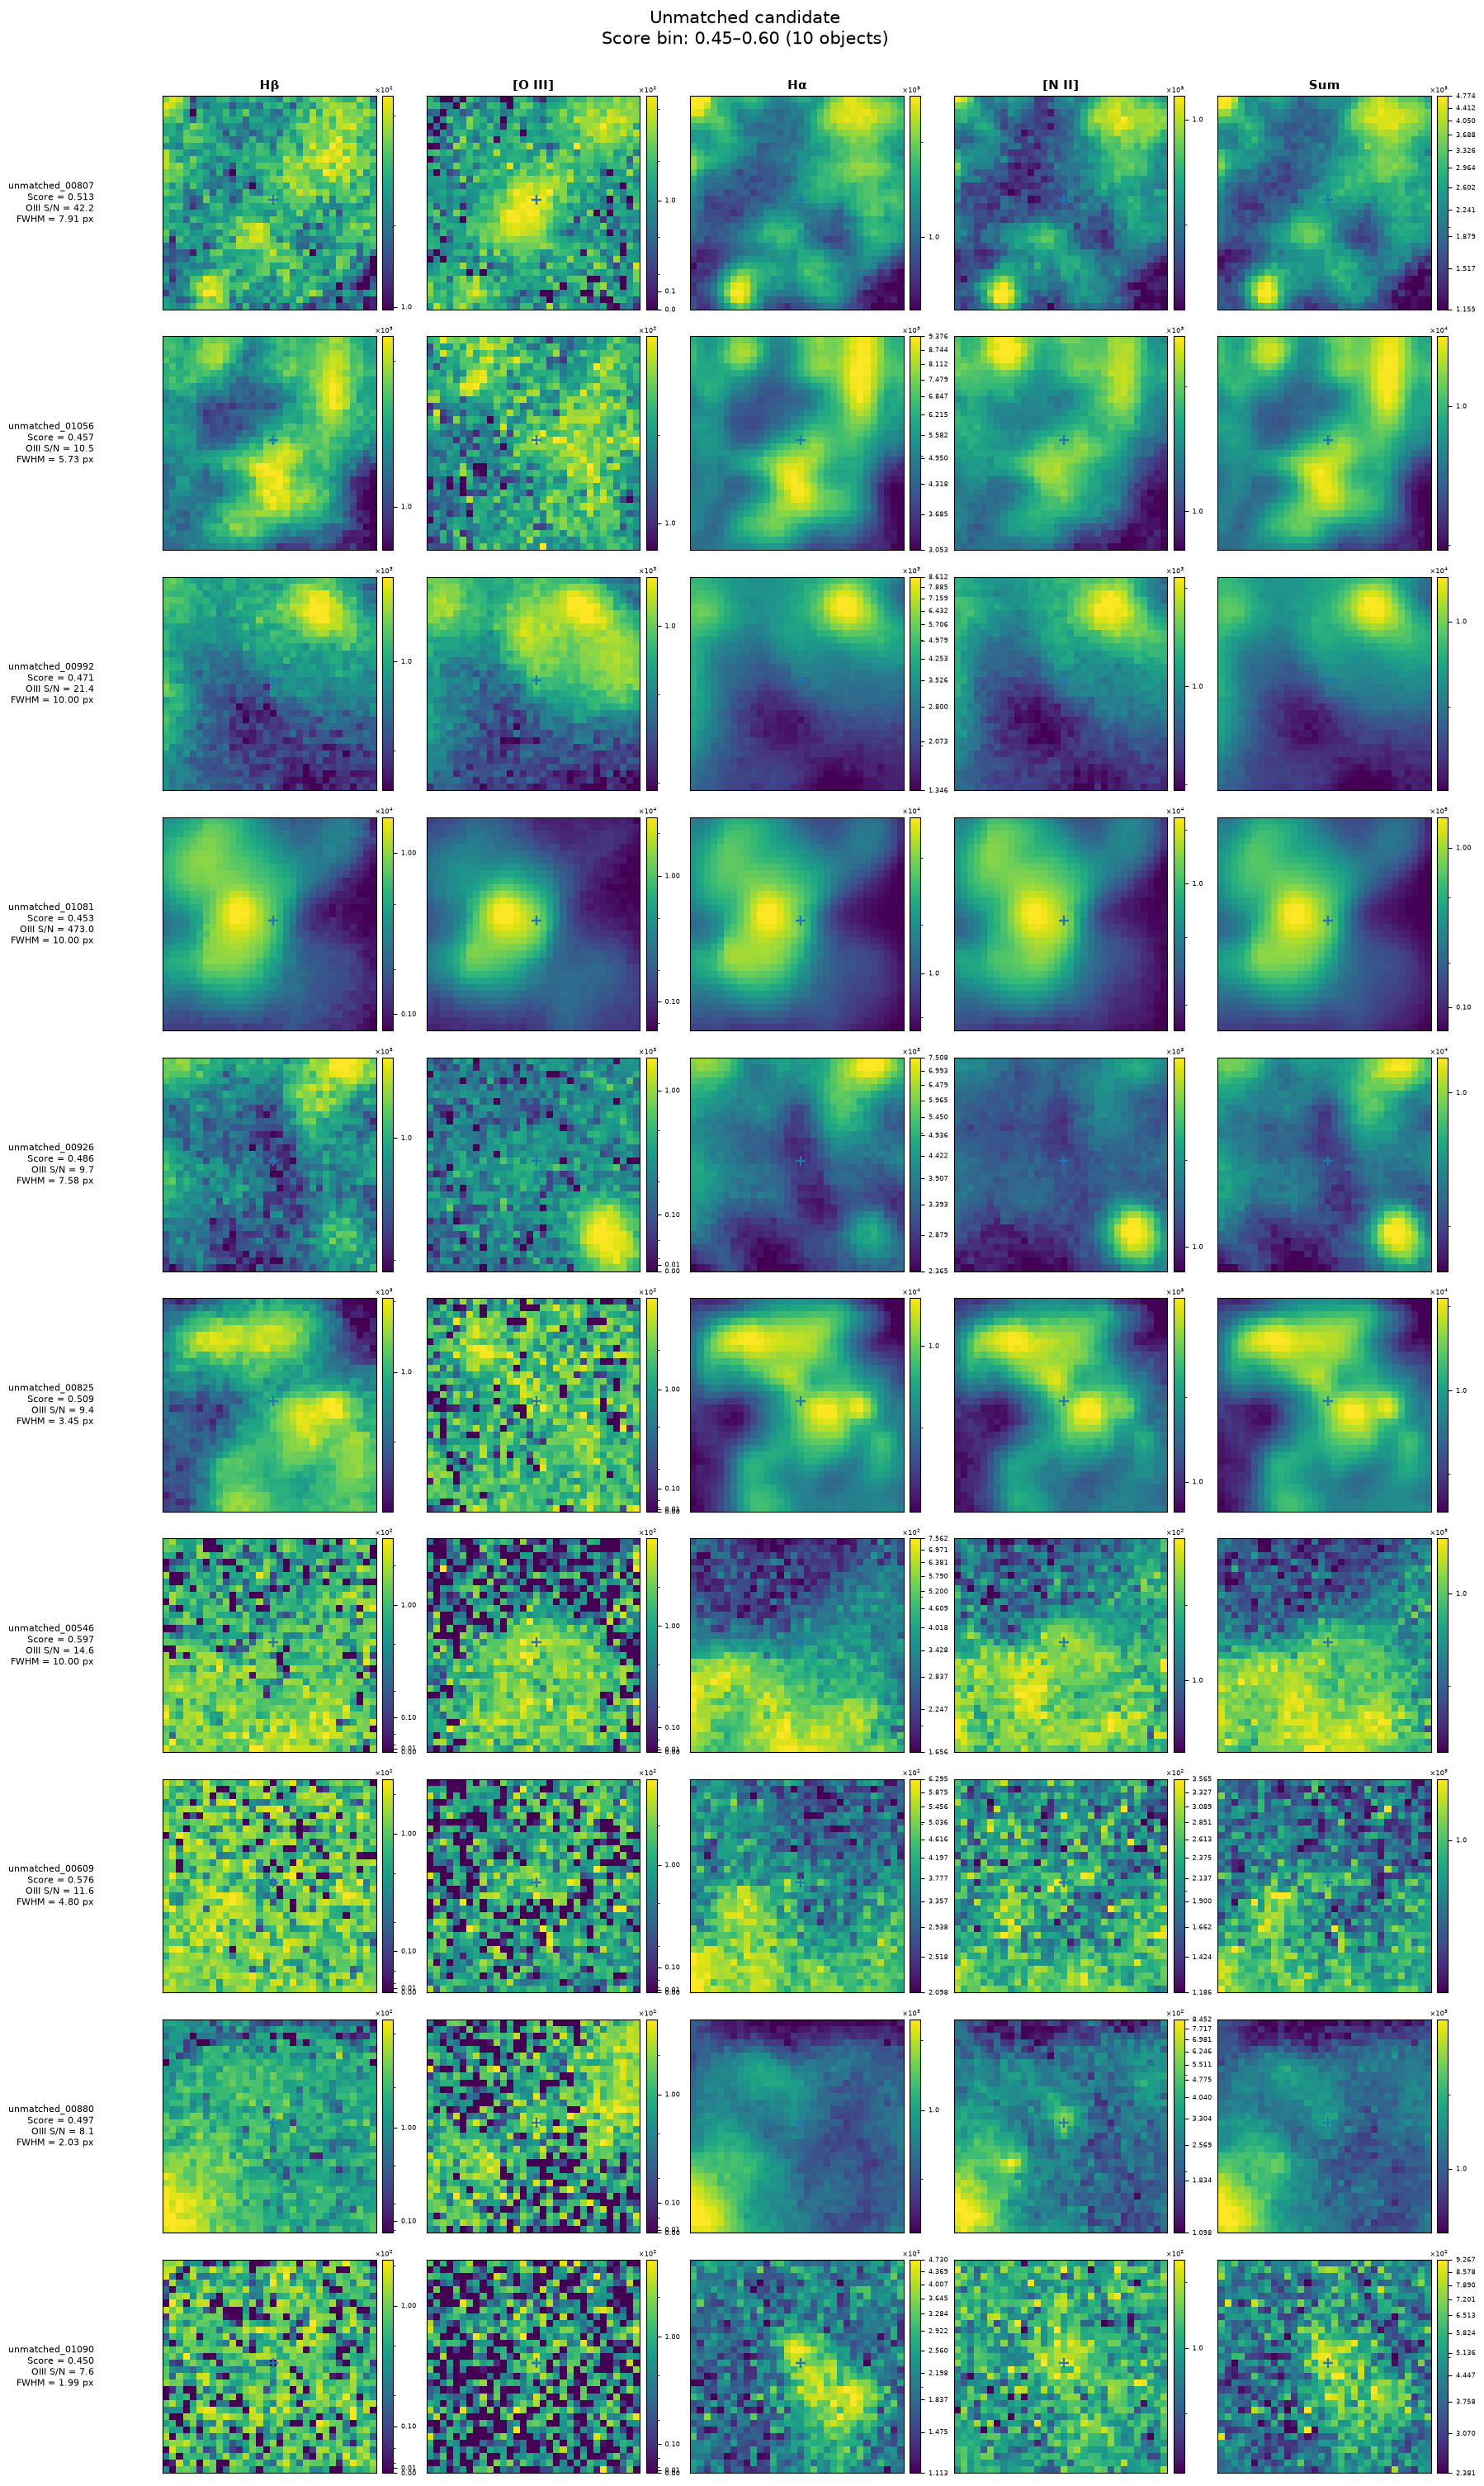

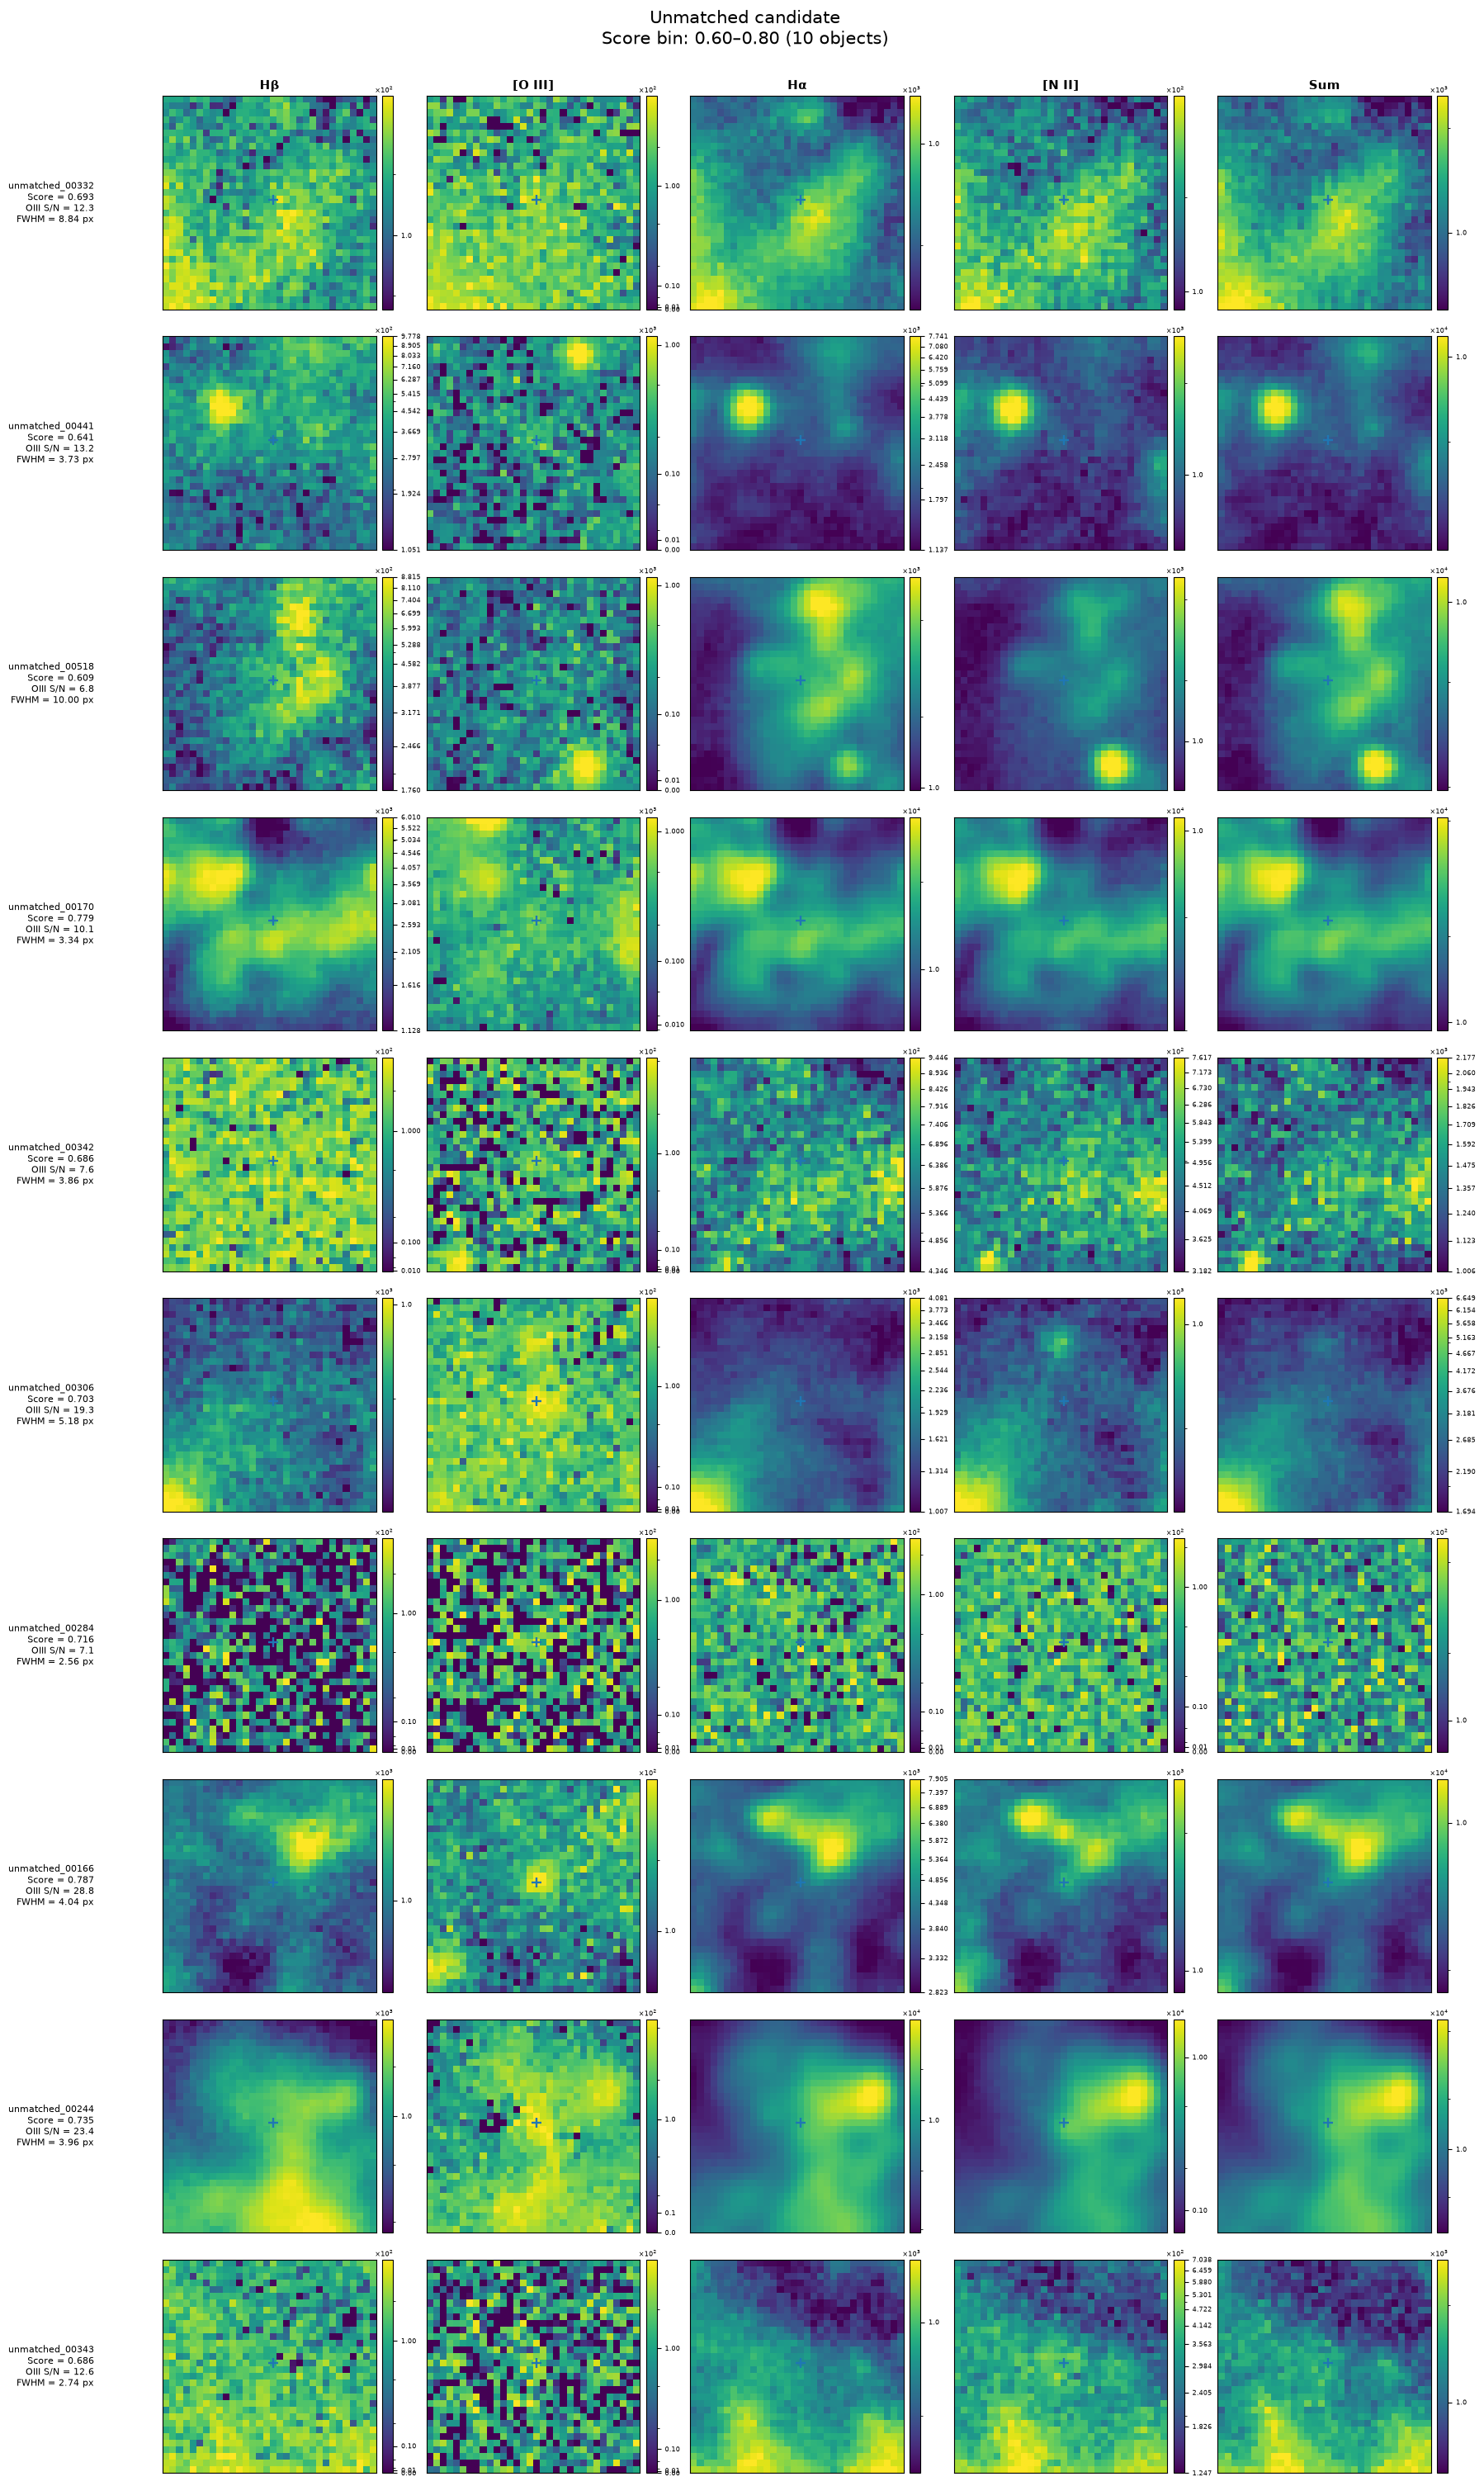

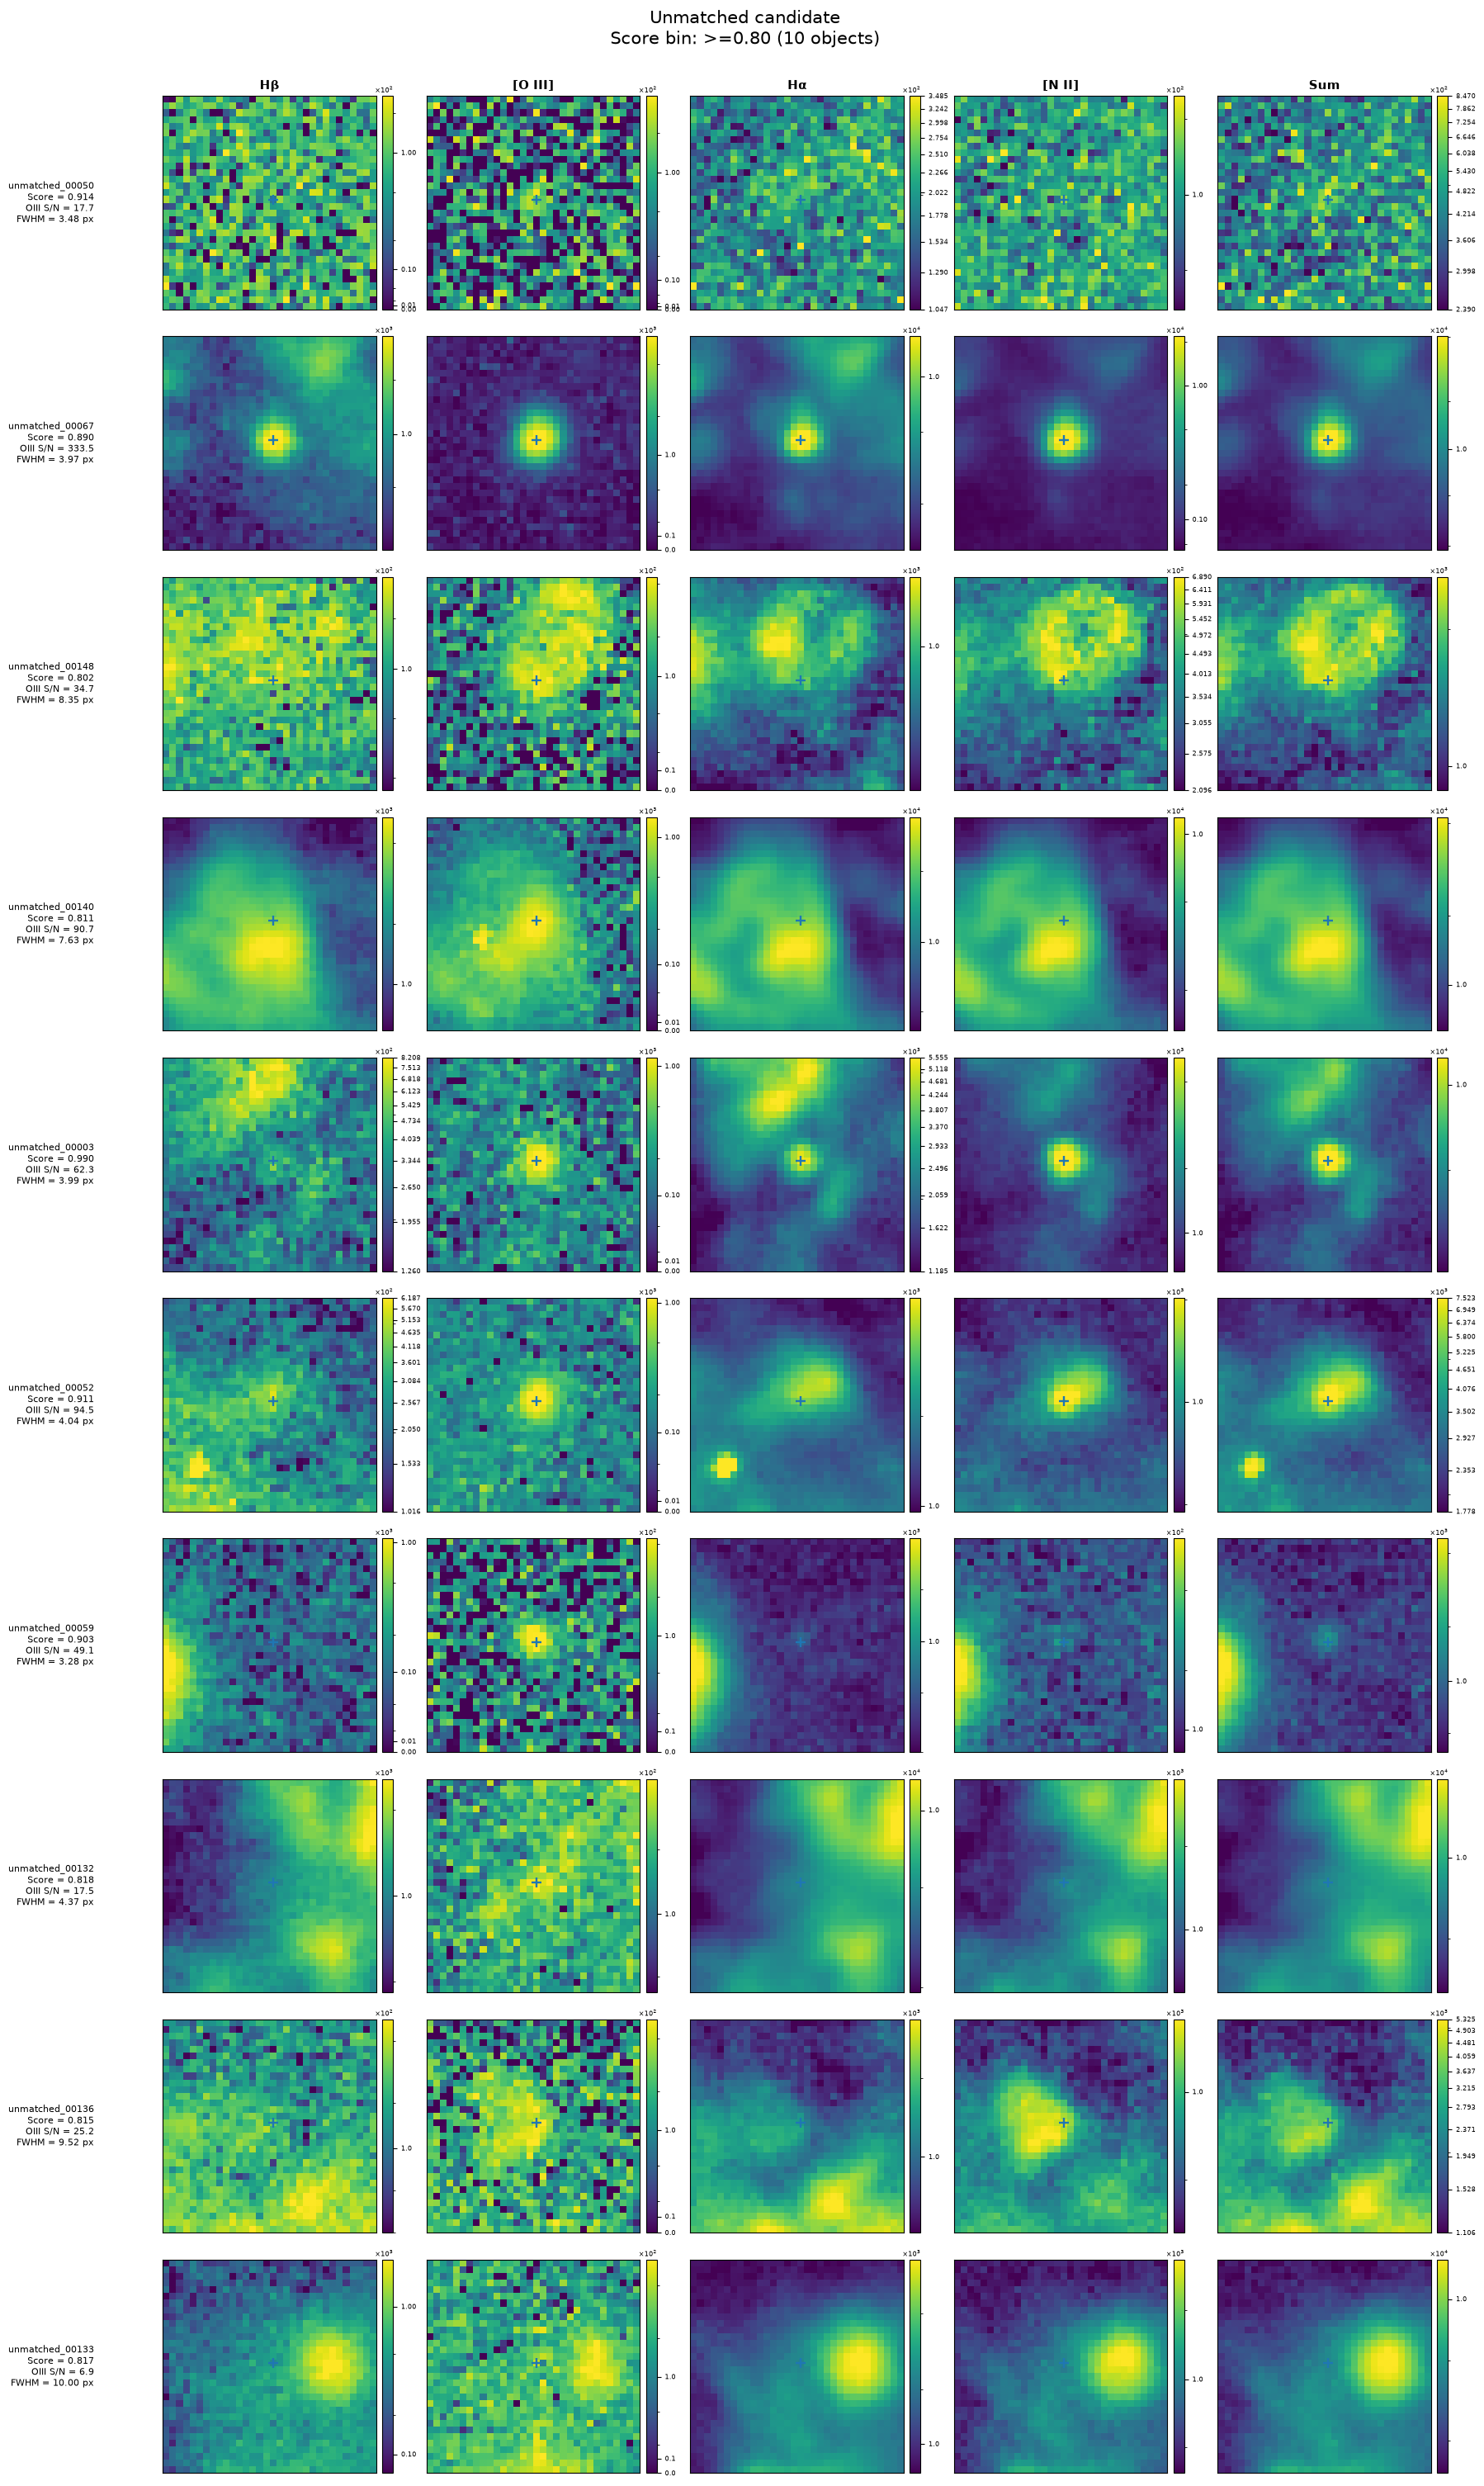

In [9]:
def add_position_markers(ax, source, population, origin):
    x0, y0 = origin
    if population in (POP_MATCHED, POP_UNMATCHED):
        ax.scatter(float(source["center_x"]) - x0, float(source["center_y"]) - y0, marker="+", s=85, linewidths=1.7)
    if population in (POP_MATCHED, POP_MISSED):
        ax.scatter(float(source["catalog_x"]) - x0, float(source["catalog_y"]) - y0, marker="x", s=70, linewidths=1.6)


def object_label(source, population):
    lines = [
        str(source["object_id"]),
        f"Score = {finite_value(source.get('network_score'), '.3f')}",
        f"OIII S/N = {finite_value(source.get('oiii_snr'), '.1f')}",
        f"FWHM = {finite_value(source.get('moffat_fwhm_pix'), '.2f')} px",
    ]
    if population == POP_MATCHED and np.isfinite(source.get("match_distance_pix", np.nan)):
        lines.append(f"Δr = {source['match_distance_pix']:.2f} px")
    return "\n".join(lines)


def add_flux_colorbar(fig, ax, image_artist):
    colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.046, pad=0.025)
    formatter = ScalarFormatter(useMathText=True)
    formatter.set_scientific(True)
    formatter.set_powerlimits((-2, 2))
    colorbar.formatter = formatter
    colorbar.update_ticks()
    colorbar.ax.tick_params(labelsize=6)
    colorbar.ax.yaxis.get_offset_text().set_fontsize(6)


def plot_score_bin(sample, population, score_bin, channel_images=channel_images):
    chosen = sample.loc[
        sample["population"].eq(population) & sample["score_bin"].eq(score_bin)
    ].reset_index(drop=True)
    if chosen.empty:
        return

    fig, axes = plt.subplots(
        len(chosen), len(channel_images), figsize=(18, 3.0 * len(chosen)), squeeze=False
    )

    for row_index, source in chosen.iterrows():
        x_center, y_center = display_center(source, population)
        label = object_label(source, population)

        for column_index, (channel_name, image) in enumerate(channel_images.items()):
            ax = axes[row_index, column_index]
            cutout, origin = extract_cutout(image, x_center, y_center)
            if cutout is None:
                ax.text(0.5, 0.5, "No cutout", ha="center", va="center")
                ax.axis("off")
                continue

            artist = ax.imshow(cutout, origin="lower", norm=make_asinh_norm(cutout))
            add_position_markers(ax, source, population, origin)

            if row_index == 0:
                ax.set_title(channel_name, fontsize=11, fontweight="bold")
            if column_index == 0:
                ax.set_ylabel(label, fontsize=8, rotation=0, ha="right", va="center", labelpad=60)
            ax.set_xticks([])
            ax.set_yticks([])
            add_flux_colorbar(fig, ax, artist)

    fig.suptitle(f"{population}\nScore bin: {score_bin} ({len(chosen)} objects)", fontsize=15, y=1.002)
    fig.tight_layout()
    safe_name = f"{population}_{score_bin}".replace("/", "-").replace(" ", "_")
    # fig.savefig(OUTPUT_DIR / f"{safe_name}.png", dpi=180, bbox_inches="tight")
    plt.show()


for population, bins, _ in sample_specs:
    for _, _, score_label in bins:
        plot_score_bin(samples_by_population[population], population, score_label)


## 8. Optional: localization error versus catalogue/source properties


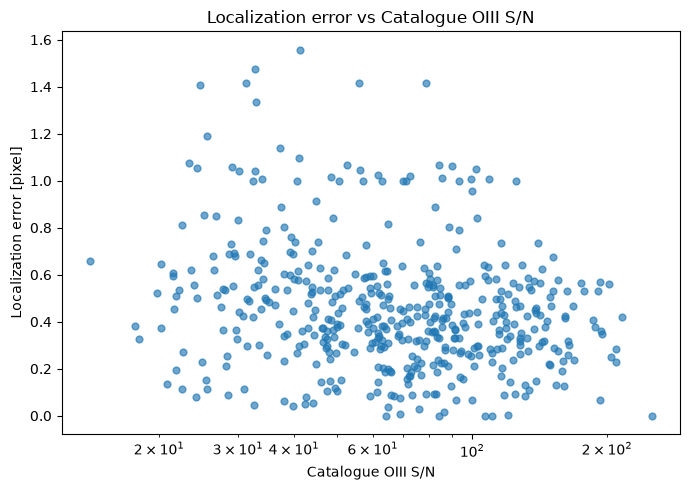

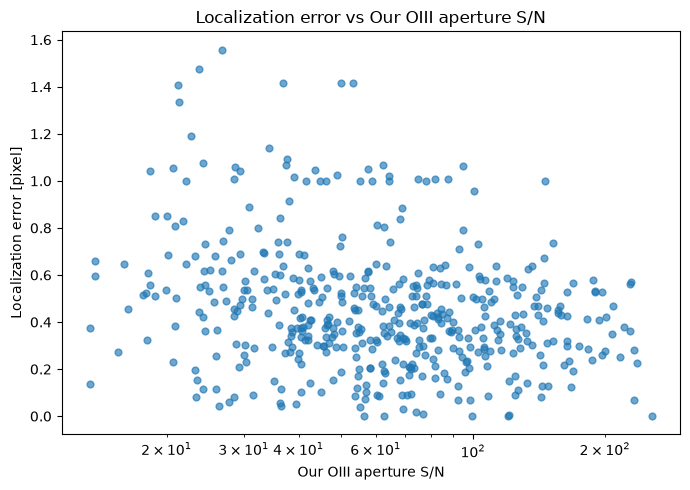

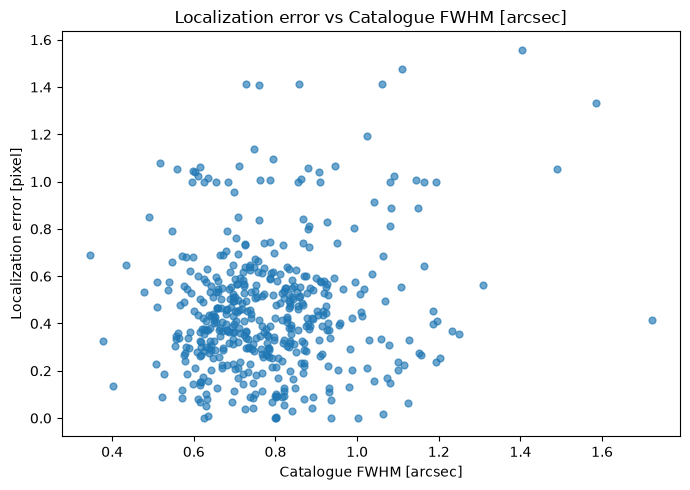

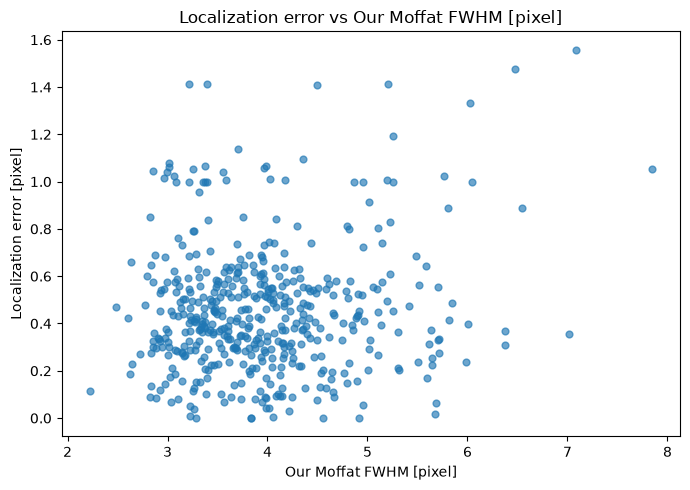

In [10]:
optional_properties = (
    ("catalog_oiii_snr", "Catalogue OIII S/N", True),
    ("oiii_snr", "Our OIII aperture S/N", True),
    ("catalog_fwhm_arcsec", "Catalogue FWHM [arcsec]", False),
    ("moffat_fwhm_pix", "Our Moffat FWHM [pixel]", False),
)

for column, xlabel, use_log_x in optional_properties:
    if column not in matched:
        continue

    valid = np.isfinite(matched[column]) & np.isfinite(matched["localization_error_pix"])
    if not valid.any():
        continue

    x = matched.loc[valid, column]
    y = matched.loc[valid, "localization_error_pix"]
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(x, y, s=24, alpha=0.65)
    if use_log_x and x.gt(0).all():
        ax.set_xscale("log")
    ax.set(xlabel=xlabel, ylabel="Localization error [pixel]", title=f"Localization error vs {xlabel}")
    fig.tight_layout()
    plt.show()


## Interpretation notes

- Radial localization error is defined only for recovered catalogue PNe.
- A non-zero mean $\Delta x$ or $\Delta y$ can indicate a systematic astrometric offset.
- The 68th, 90th, and 95th percentiles are more informative than the maximum for typical localization performance.
- Recovered cutouts help distinguish model offsets from blending or catalogue/astrometric uncertainty.
- Missed and unmatched samples are qualitative comparisons and do not have catalogue-defined localization errors.
